<a href="https://colab.research.google.com/github/ayooluwaestheraladetuyi-cpu/aiyetoro-shoreline-analysis/blob/main/Aiyetoro_XGBoost_SHAP_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
print("Aiyetoro Shoreline Change Analysis")
print("Study period: 2015–2025")
print("Study area: Aiyetoro, Ilaje, Ondo State, Nigeria")

Aiyetoro Shoreline Change Analysis
Study period: 2015–2025
Study area: Aiyetoro, Ilaje, Ondo State, Nigeria


In [8]:
!pip install xgboost shap pandas numpy matplotlib scikit-learn geopandas

In [9]:
import pandas as pd
import numpy as np
import geopandas as gpd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

print("All libraries imported successfully!")
print("Ready to prepare the Aiyetoro shoreline data.")

All libraries imported successfully!
Ready to prepare the Aiyetoro shoreline data.


In [10]:
from google.colab import files

uploaded = files.upload()

Saving Shoreline_2015_Metres.gpkg..gpkg to Shoreline_2015_Metres.gpkg..gpkg
Saving Shoreline_2016_Metres.gpkg to Shoreline_2016_Metres.gpkg
Saving Shoreline_2017_Metres.gpkg to Shoreline_2017_Metres.gpkg
Saving Shoreline_2018_Metres.gpkg to Shoreline_2018_Metres.gpkg
Saving Shoreline_2025_Metres.gpkg..gpkg to Shoreline_2025_Metres.gpkg..gpkg


In [11]:
import geopandas as gpd
import os

# List the uploaded files
print("Checking uploaded shoreline files...\n")

for filename in uploaded.keys():
    print(filename)

Checking uploaded shoreline files...

Shoreline_2015_Metres.gpkg..gpkg
Shoreline_2016_Metres.gpkg
Shoreline_2017_Metres.gpkg
Shoreline_2018_Metres.gpkg
Shoreline_2025_Metres.gpkg..gpkg


In [24]:
import geopandas as gpd

years = [2015, 2016, 2017, 2018, 2025]

for year in years:
    filename = f"Shoreline_{year}_Metres.gpkg.gpkg"

    if os.path.exists(filename):
        gdf = gpd.read_file(filename)

        print(f"\nYEAR: {year}")
        print("Features:", len(gdf))
        print("CRS:", gdf.crs)
        print("Geometry types:", gdf.geometry.geom_type.value_counts().to_dict())
        print("Bounds:", gdf.total_bounds)
    else:
        print(f"\nFile not found: {filename}")


File not found: Shoreline_2015_Metres.gpkg.gpkg

File not found: Shoreline_2016_Metres.gpkg.gpkg

File not found: Shoreline_2017_Metres.gpkg.gpkg

File not found: Shoreline_2018_Metres.gpkg.gpkg

File not found: Shoreline_2025_Metres.gpkg.gpkg


In [13]:
import os

print("Files currently available in Colab:\n")

for filename in os.listdir("/content"):
    print(filename)

Files currently available in Colab:

.config
Shoreline_2018_Metres.gpkg
Shoreline_2025_Metres.gpkg..gpkg
Shoreline_2016_Metres.gpkg
Shoreline_2015_Metres.gpkg..gpkg
Shoreline_2017_Metres.gpkg
sample_data


In [14]:
import os

files = [
    f for f in os.listdir("/content")
    if f.lower().endswith((".gpkg", ".gpkg.gpkg"))
]

print("SHORELINE FILES FOUND:", len(files))

for f in files:
    print(repr(f))

SHORELINE FILES FOUND: 5
'Shoreline_2018_Metres.gpkg'
'Shoreline_2025_Metres.gpkg..gpkg'
'Shoreline_2016_Metres.gpkg'
'Shoreline_2015_Metres.gpkg..gpkg'
'Shoreline_2017_Metres.gpkg'


In [15]:
import os
import geopandas as gpd

# Find the uploaded GeoPackage files
files = [
    os.path.join("/content", f)
    for f in os.listdir("/content")
    if f.lower().endswith(".gpkg")
]

print("Number of GeoPackage files found:", len(files))

# Inspect each file
for path in files:
    try:
        gdf = gpd.read_file(path)

        print("\nFile:", os.path.basename(path))
        print("Number of features:", len(gdf))
        print("Coordinate reference system:", gdf.crs)
        print("Geometry types:", gdf.geometry.geom_type.value_counts().to_dict())
        print("Columns:", list(gdf.columns))

    except Exception as e:
        print("\nCould not read:", os.path.basename(path))
        print("Error:", e)

Number of GeoPackage files found: 5

File: Shoreline_2018_Metres.gpkg
Number of features: 17
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 17}
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']

File: Shoreline_2025_Metres.gpkg..gpkg
Number of features: 10
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 10}
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']

File: Shoreline_2016_Metres.gpkg
Number of features: 1
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 1}
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']

File: Shoreline_2015_Metres.gpkg..gpkg
Number of features: 7
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 7}
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']

File: Shoreline_2017_Metres.gpkg
Number of features: 25
Coordinate reference system: EPSG:32631
Geometry types: {'MultiLineString': 25}
Columns

In [16]:
print("Files found:", len(files))

for path in files:
    gdf = gpd.read_file(path)
    print(os.path.basename(path), "| CRS:", gdf.crs,
          "| Geometry:", list(gdf.geometry.geom_type.unique()))

Files found: 5
Shoreline_2018_Metres.gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']
Shoreline_2025_Metres.gpkg..gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']
Shoreline_2016_Metres.gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']
Shoreline_2015_Metres.gpkg..gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']
Shoreline_2017_Metres.gpkg | CRS: EPSG:32631 | Geometry: ['MultiLineString']


In [17]:
import os
import geopandas as gpd
import pandas as pd

results = []

for path in files:
    gdf = gpd.read_file(path)

    # Calculate total length in metres
    total_length_m = gdf.geometry.length.sum()

    # Identify the year from the filename
    filename = os.path.basename(path)
    year = next(
        (y for y in [2015, 2016, 2017, 2018, 2025]
         if str(y) in filename),
        None
    )

    results.append({
        "Year": year,
        "Number_of_features": len(gdf),
        "Total_mapped_length_m": round(total_length_m, 2),
        "Total_mapped_length_km": round(total_length_m / 1000, 3)
    })

shoreline_summary = pd.DataFrame(results).sort_values("Year")

display(shoreline_summary)

,Year,Number_of_features,Total_mapped_length_m,Total_mapped_length_km
3,2015,7,24034.49,24.034
2,2016,1,13478.40,13.478
4,2017,25,42462.74,42.463
0,2018,17,30117.64,30.118
1,2025,10,15744.89,15.745


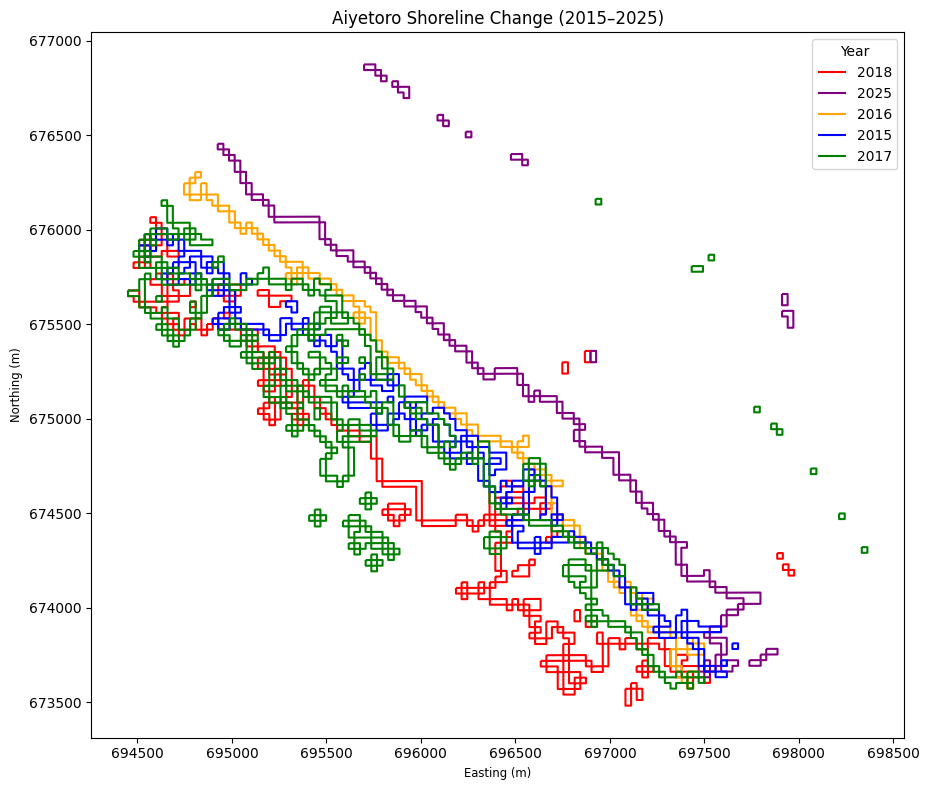

In [18]:
import matplotlib.pyplot as plt
import geopandas as gpd
import os

# Match the colours used in QGIS
shoreline_colors = {
    2015: "#0000FF",  # Blue
    2016: "#FFA500",  # Orange
    2017: "#008000",  # Green
    2018: "#FF0000",  # Red
    2025: "#800080"   # Purple
}

fig, ax = plt.subplots(figsize=(12, 8))

for path in files:
    gdf = gpd.read_file(path)

    filename = os.path.basename(path)

    year = next(
        (y for y in shoreline_colors if str(y) in filename),
        None
    )

    if year is not None:
        gdf.plot(
            ax=ax,
            color=shoreline_colors[year],
            linewidth=1.5,
            label=str(year)
        )

ax.set_title("Aiyetoro Shoreline Change (2015–2025)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [19]:
import geopandas as gpd
import pandas as pd
import os

summary = []

for path in files:
    gdf = gpd.read_file(path)

    year = next(
        (y for y in [2015, 2016, 2017, 2018, 2025]
         if str(y) in os.path.basename(path)),
        None
    )

    summary.append({
        "Year": year,
        "Features": len(gdf),
        "Empty geometries": gdf.geometry.is_empty.sum(),
        "Invalid geometries": (~gdf.geometry.is_valid).sum(),
        "CRS": str(gdf.crs),
        "Total length (m)": round(gdf.geometry.length.sum(), 2)
    })

display(pd.DataFrame(summary).sort_values("Year"))

,Year,Features,Empty geometries,Invalid geometries,CRS,Total length (m)
3,2015,7,0,0,EPSG:32631,24034.49
2,2016,1,0,0,EPSG:32631,13478.40
4,2017,25,0,0,EPSG:32631,42462.74
0,2018,17,0,0,EPSG:32631,30117.64
1,2025,10,0,0,EPSG:32631,15744.89


In [20]:
import geopandas as gpd
import pandas as pd
import os

segment_results = []

for path in files:
    gdf = gpd.read_file(path)

    year = next(
        (y for y in [2015, 2016, 2017, 2018, 2025]
         if str(y) in os.path.basename(path)),
        None
    )

    for i, geom in enumerate(gdf.geometry):
        segment_results.append({
            "Year": year,
            "Feature_ID": i + 1,
            "Length_m": round(geom.length, 2)
        })

segments = pd.DataFrame(segment_results)

display(
    segments.sort_values(["Year", "Length_m"])
    .reset_index(drop=True)
)

,Year,Feature_ID,Length_m
0,2015,4,119.28
1,2015,5,119.28
2,2015,6,119.28
3,2015,7,119.28
4,2015,2,238.55
5,2015,3,238.55
6,2015,1,23080.28
7,2016,1,13478.40
8,2017,1,119.27
9,2017,10,119.28


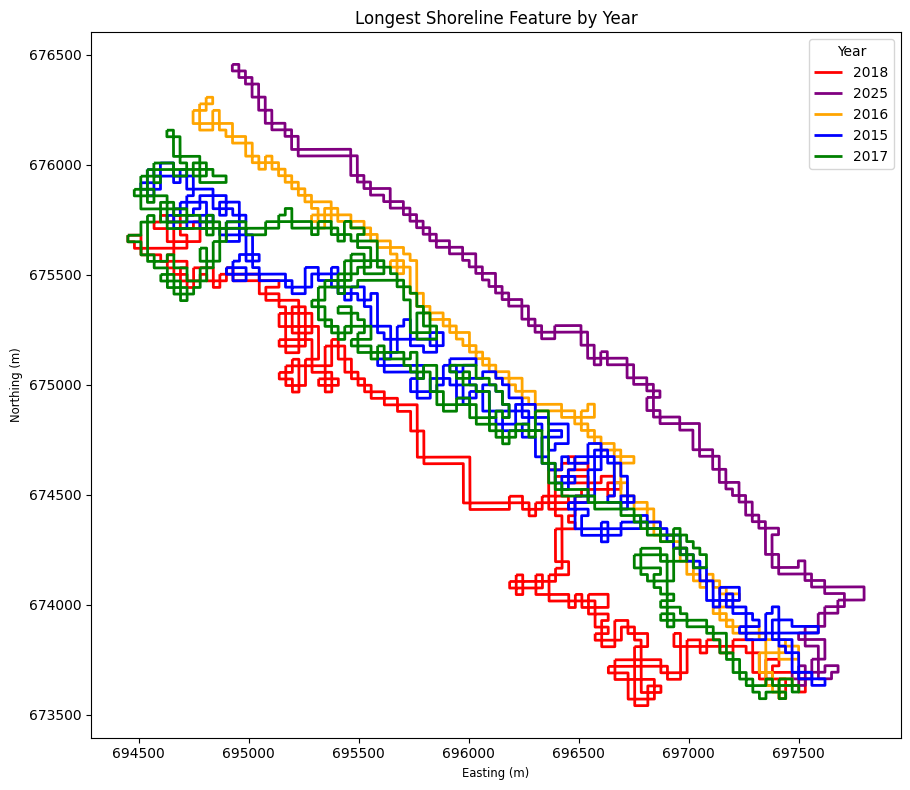

In [21]:
import geopandas as gpd
import matplotlib.pyplot as plt
import os

shoreline_colors = {
    2015: "#0000FF",  # Blue
    2016: "#FFA500",  # Orange
    2017: "#008000",  # Green
    2018: "#FF0000",  # Red
    2025: "#800080"   # Purple
}

fig, ax = plt.subplots(figsize=(12, 8))

for path in files:
    gdf = gpd.read_file(path)

    year = next(
        (y for y in shoreline_colors
         if str(y) in os.path.basename(path)),
        None
    )

    if year is None or gdf.empty:
        continue

    # Select the longest feature for visual inspection
    longest = gdf.loc[[gdf.geometry.length.idxmax()]]

    longest.plot(
        ax=ax,
        color=shoreline_colors[year],
        linewidth=2,
        label=str(year)
    )

ax.set_title("Longest Shoreline Feature by Year")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [22]:
import geopandas as gpd
import pandas as pd
import os

extent_results = []

for path in files:
    gdf = gpd.read_file(path)

    minx, miny, maxx, maxy = gdf.total_bounds

    year = next(
        (y for y in [2015, 2016, 2017, 2018, 2025]
         if str(y) in os.path.basename(path)),
        None
    )

    extent_results.append({
        "Year": year,
        "Min_Easting": round(minx, 2),
        "Min_Northing": round(miny, 2),
        "Max_Easting": round(maxx, 2),
        "Max_Northing": round(maxy, 2)
    })

extent_df = pd.DataFrame(extent_results).sort_values("Year")

display(extent_df)

,Year,Min_Easting,Min_Northing,Max_Easting,Max_Northing
3,2015,694508.85,673633.27,697678.23,676008.12
2,2016,694746.44,673573.16,697499.33,676306.75
4,2017,694449.97,673572.87,698362.73,676164.70
0,2018,694449.97,673482.67,697975.29,676067.54
1,2025,694924.75,673633.07,697970.93,676876.08


In [27]:
import os
import geopandas as gpd

files = [
    os.path.join("/content", f)
    for f in os.listdir("/content")
    if f.lower().endswith(".gpkg")
]

print("Shoreline files found:", len(files))

for f in files:
    print(os.path.basename(f))

Shoreline files found: 5
Shoreline_2018_Metres.gpkg
Shoreline_2025_Metres.gpkg..gpkg
Shoreline_2016_Metres.gpkg
Shoreline_2015_Metres.gpkg..gpkg
Shoreline_2017_Metres.gpkg


In [28]:
import os
import geopandas as gpd

files = [
    os.path.join("/content", f)
    for f in os.listdir("/content")
    if f.lower().endswith(".gpkg")
]

for path in sorted(files):
    gdf = gpd.read_file(path)

    print("\nFile:", os.path.basename(path))
    print("Year:", gdf["year"].iloc[0] if "year" in gdf.columns else "Not specified")
    print("Coordinate system:", gdf.crs)
    print("Geometry type:", gdf.geom_type.unique())
    print("Number of features:", len(gdf))
    print("Total length (metres, if CRS uses metres):", round(gdf.to_crs("EPSG:32631").length.sum(), 2))


File: Shoreline_2015_Metres.gpkg..gpkg
Year: 2015
Coordinate system: EPSG:32631
Geometry type: ['MultiLineString']
Number of features: 7
Total length (metres, if CRS uses metres): 24034.49

File: Shoreline_2016_Metres.gpkg
Year: 2016
Coordinate system: EPSG:32631
Geometry type: ['MultiLineString']
Number of features: 1
Total length (metres, if CRS uses metres): 13478.4

File: Shoreline_2017_Metres.gpkg
Year: 2017
Coordinate system: EPSG:32631
Geometry type: ['MultiLineString']
Number of features: 25
Total length (metres, if CRS uses metres): 42462.74

File: Shoreline_2018_Metres.gpkg
Year: 2018
Coordinate system: EPSG:32631
Geometry type: ['MultiLineString']
Number of features: 17
Total length (metres, if CRS uses metres): 30117.64

File: Shoreline_2025_Metres.gpkg..gpkg
Year: 2025
Coordinate system: EPSG:32631
Geometry type: ['MultiLineString']
Number of features: 10
Total length (metres, if CRS uses metres): 15744.89


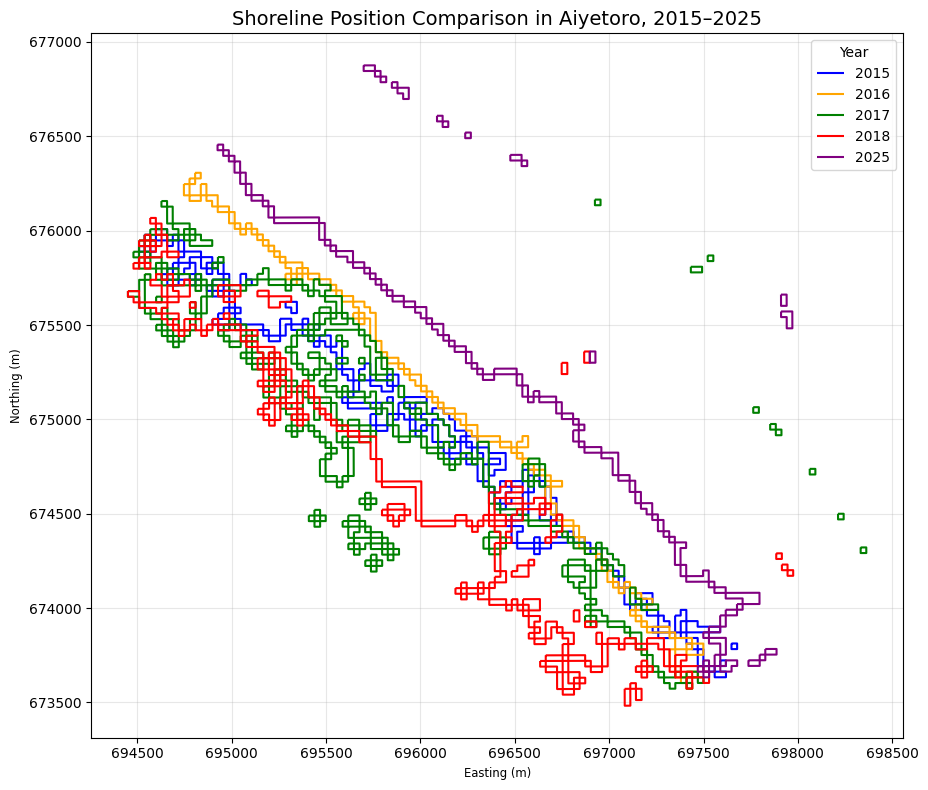

In [30]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt

# Colours for each year
year_colors = {
    2015: "blue",
    2016: "orange",
    2017: "green",
    2018: "red",
    2025: "purple"
}

# Create the map
fig, ax = plt.subplots(figsize=(12, 8))

for path in sorted(files):
    gdf = gpd.read_file(path)

    year = int(gdf["year"].iloc[0])

    gdf.plot(
        ax=ax,
        color=year_colors.get(year, "black"),
        linewidth=1.5,
        label=str(year)
    )

ax.set_title(
    "Shoreline Position Comparison in Aiyetoro, 2015–2025",
    fontsize=14
)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

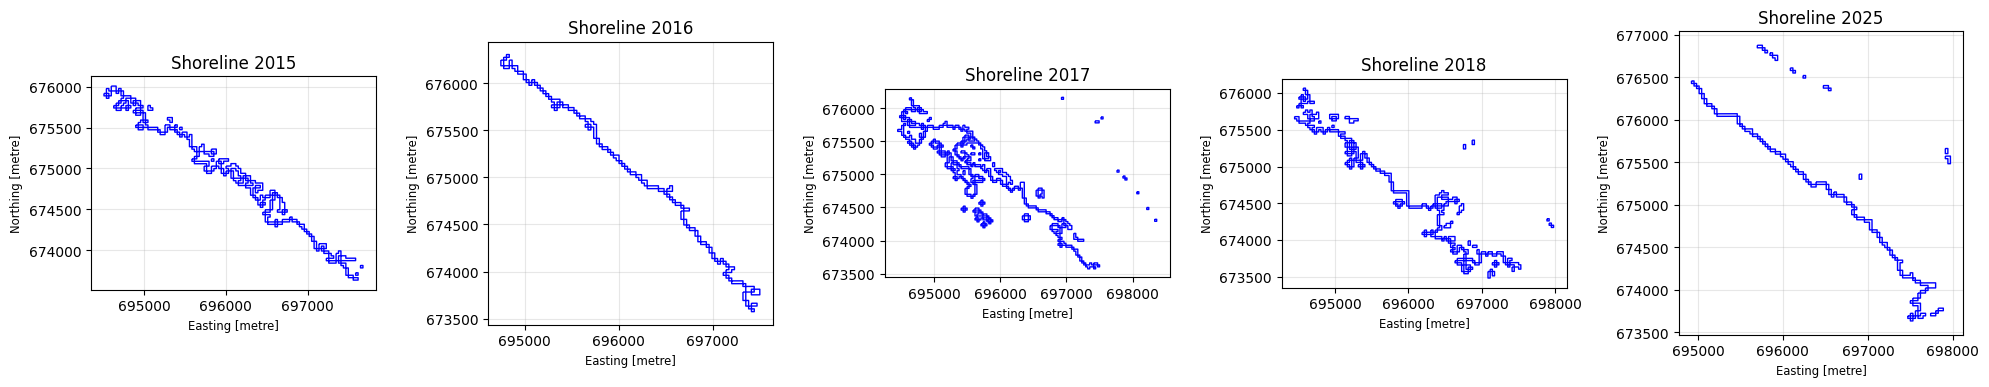

In [31]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

years_to_check = [2015, 2016, 2017, 2018, 2025]

for ax, year in zip(axes, years_to_check):
    matching_files = [
        f for f in files
        if str(year) in os.path.basename(f)
    ]

    if not matching_files:
        ax.set_title(f"{year}: File not found")
        continue

    gdf = gpd.read_file(matching_files[0])

    gdf.plot(
        ax=ax,
        color="blue",
        linewidth=1
    )

    ax.set_title(f"Shoreline {year}")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Reference line length: 506.94 metres
Number of transects: 5
Transect spacing: 100 metres
Transect length: 1000 metres


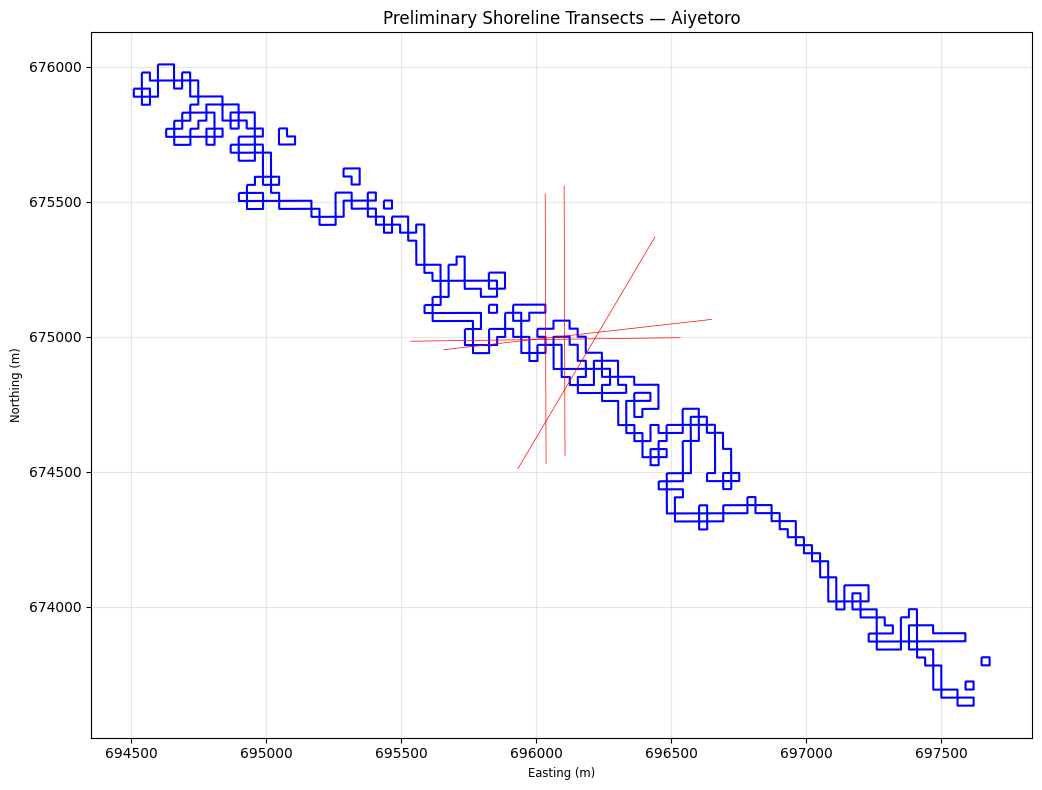

In [32]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

from shapely.geometry import LineString
from shapely.ops import linemerge

# Load the 2015 shoreline
path_2015 = next(
    f for f in files
    if "2015" in os.path.basename(f)
)

shoreline_2015 = gpd.read_file(path_2015).to_crs("EPSG:32631")

# Merge connected shoreline segments
merged = linemerge(shoreline_2015.geometry.union_all())

# Extract individual line components
if merged.geom_type == "LineString":
    line_parts = [merged]
elif merged.geom_type == "MultiLineString":
    line_parts = list(merged.geoms)
else:
    line_parts = [
        geom for geom in merged.geoms
        if geom.geom_type == "LineString"
    ]

# Select the longest connected line as the preliminary reference
reference_line = max(line_parts, key=lambda line: line.length)

print("Reference line length:", round(reference_line.length, 2), "metres")

# Generate transects every 100 metres
spacing = 100
half_length = 500
transects = []

for distance in np.arange(20, reference_line.length - 20, spacing):

    point = reference_line.interpolate(distance)

    # Estimate the local shoreline direction
    before = reference_line.interpolate(distance - 10)
    after = reference_line.interpolate(distance + 10)

    dx = after.x - before.x
    dy = after.y - before.y

    magnitude = np.hypot(dx, dy)

    if magnitude == 0:
        continue

    # Unit vector perpendicular to the shoreline
    nx = -dy / magnitude
    ny = dx / magnitude

    # Draw 500 metres on either side of the reference line
    transect = LineString([
        (
            point.x - nx * half_length,
            point.y - ny * half_length
        ),
        (
            point.x + nx * half_length,
            point.y + ny * half_length
        )
    ])

    transects.append(transect)

# Create a GeoDataFrame
transect_gdf = gpd.GeoDataFrame(
    {"transect_id": range(1, len(transects) + 1)},
    geometry=transects,
    crs="EPSG:32631"
)

print("Number of transects:", len(transect_gdf))
print("Transect spacing:", spacing, "metres")
print("Transect length:", half_length * 2, "metres")

# Plot the reference shoreline and transects
fig, ax = plt.subplots(figsize=(12, 8))

shoreline_2015.plot(
    ax=ax,
    color="blue",
    linewidth=1.5,
    label="2015 shoreline"
)

transect_gdf.plot(
    ax=ax,
    color="red",
    linewidth=0.5
)

ax.set_title("Preliminary Shoreline Transects — Aiyetoro")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Shoreline sections: 258
Transects generated: 352


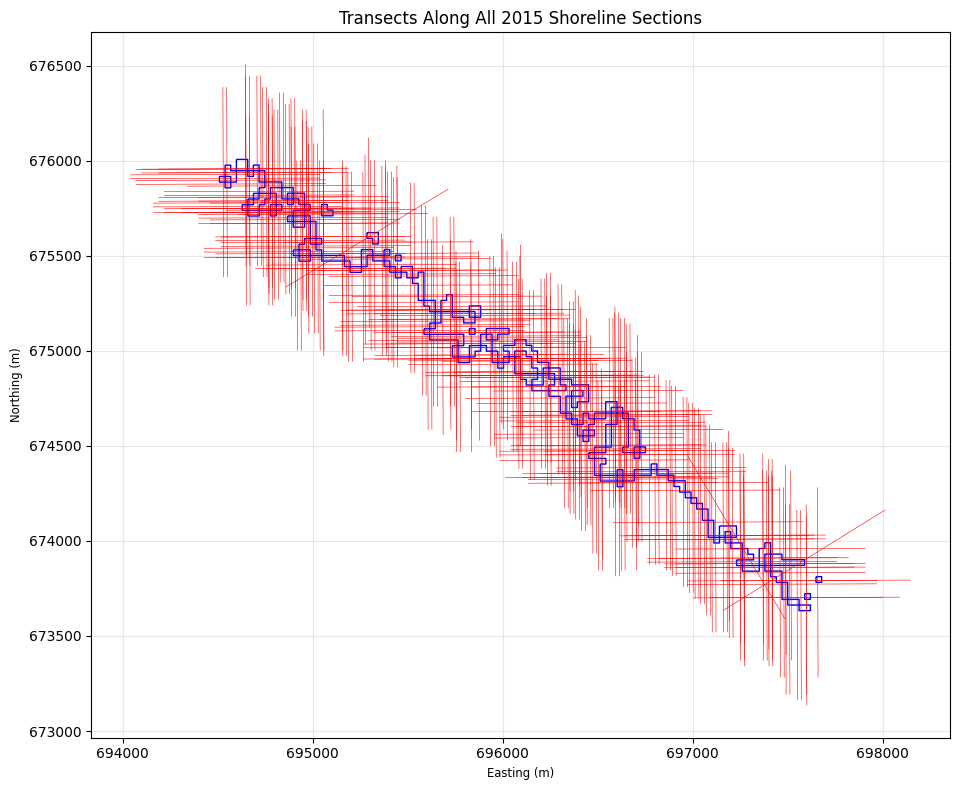

In [34]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import LineString
from shapely.ops import linemerge

# Merge the 2015 shoreline segments where possible
merged = linemerge(shoreline_2015.geometry.union_all())

# Get all available shoreline lines
if merged.geom_type == "LineString":
    line_parts = [merged]
elif merged.geom_type == "MultiLineString":
    line_parts = list(merged.geoms)
else:
    line_parts = [
        geom for geom in merged.geoms
        if geom.geom_type == "LineString"
    ]

spacing = 100
half_length = 500
transects = []

# Generate transects along every line section
for line in line_parts:

    if line.length < 20:
        continue

    for distance in np.arange(10, line.length, spacing):

        point = line.interpolate(distance)

        before = line.interpolate(max(0, distance - 5))
        after = line.interpolate(min(line.length, distance + 5))

        dx = after.x - before.x
        dy = after.y - before.y
        magnitude = np.hypot(dx, dy)

        if magnitude == 0:
            continue

        nx = -dy / magnitude
        ny = dx / magnitude

        transect = LineString([
            (point.x - nx * half_length,
             point.y - ny * half_length),
            (point.x + nx * half_length,
             point.y + ny * half_length)
        ])

        transects.append(transect)

transect_gdf = gpd.GeoDataFrame(
    {"transect_id": range(1, len(transects) + 1)},
    geometry=transects,
    crs="EPSG:32631"
)

print("Shoreline sections:", len(line_parts))
print("Transects generated:", len(transect_gdf))

# Plot the results
fig, ax = plt.subplots(figsize=(12, 8))

shoreline_2015.plot(
    ax=ax,
    color="blue",
    linewidth=1,
    label="2015 shoreline"
)

transect_gdf.plot(
    ax=ax,
    color="red",
    linewidth=0.4
)

ax.set_title("Transects Along All 2015 Shoreline Sections")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
import os
import geopandas as gpd
import pandas as pd

years = [2015, 2016, 2017, 2018, 2025]

intersection_results = []

for year in years:

    path = next(
        f for f in files
        if str(year) in os.path.basename(f)
    )

    shoreline = gpd.read_file(path).to_crs("EPSG:32631")

    # Combine the shoreline geometries
    shoreline_line = shoreline.geometry.union_all()

    for _, transect in transect_gdf.iterrows():

        intersection = transect.geometry.intersection(shoreline_line)

        if intersection.is_empty:
            count = 0
        elif intersection.geom_type == "Point":
            count = 1
        elif intersection.geom_type == "MultiPoint":
            count = len(intersection.geoms)
        elif intersection.geom_type == "GeometryCollection":
            count = sum(
                1 for geom in intersection.geoms
                if geom.geom_type == "Point"
            )
        else:
            count = 1

        intersection_results.append({
            "Year": year,
            "Transect_ID": transect["transect_id"],
            "Intersection_Count": count
        })

intersection_df = pd.DataFrame(intersection_results)

summary = (
    intersection_df
    .groupby("Year")["Intersection_Count"]
    .agg(
        Total_Transects="count",
        No_Intersection=lambda x: (x == 0).sum(),
        One_Intersection=lambda x: (x == 1).sum(),
        Multiple_Intersections=lambda x: (x > 1).sum()
    )
)

print(summary)

      Total_Transects  No_Intersection  One_Intersection  \
Year                                                       
2015              352                0                 0   
2016              352               56                16   
2017              352                7                 1   
2018              352               43                14   
2025              352              282                13   

      Multiple_Intersections  
Year                          
2015                     352  
2016                     280  
2017                     344  
2018                     295  
2025                      57  


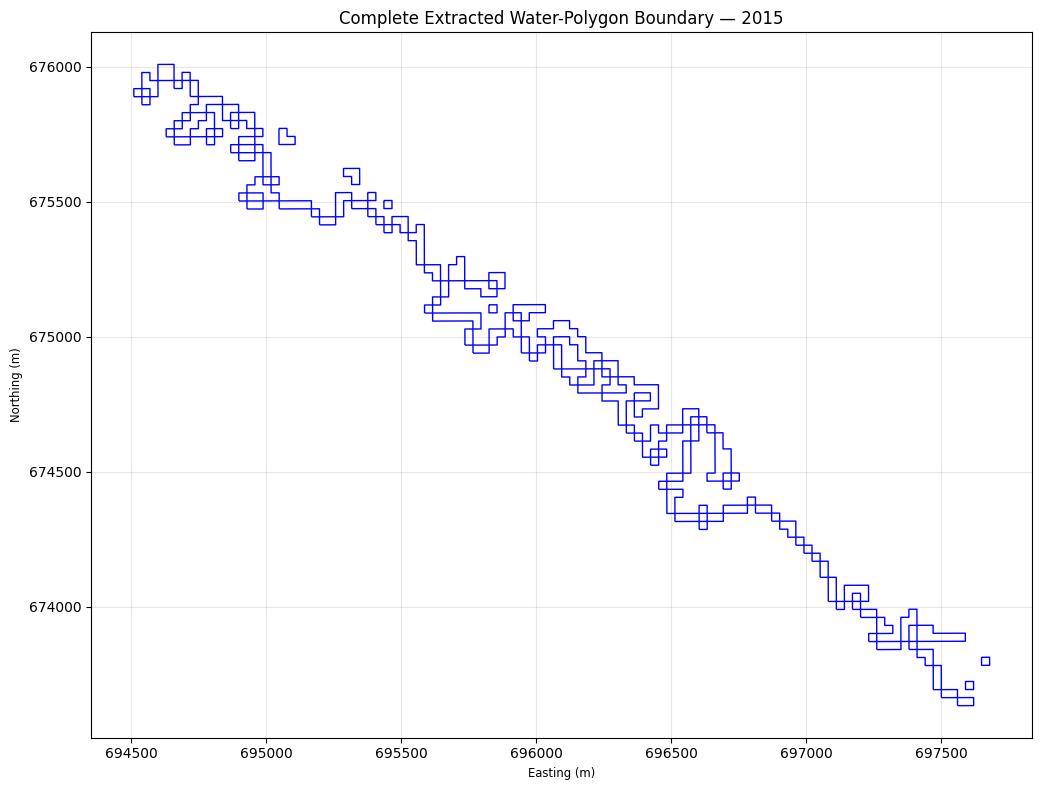

Geometry type: MultiLineString
Total boundary length: 24034.49 metres


In [36]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Combine all 2015 shoreline features
shoreline_2015 = gpd.read_file(
    next(f for f in files if "2015" in f)
).to_crs("EPSG:32631")

combined = shoreline_2015.geometry.union_all()

# Plot the complete extracted boundary
fig, ax = plt.subplots(figsize=(12, 8))

gpd.GeoSeries(
    [combined],
    crs=shoreline_2015.crs
).plot(ax=ax, color="blue", linewidth=1)

ax.set_title("Complete Extracted Water-Polygon Boundary — 2015")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Geometry type:", combined.geom_type)
print("Total boundary length:", round(combined.length, 2), "metres")

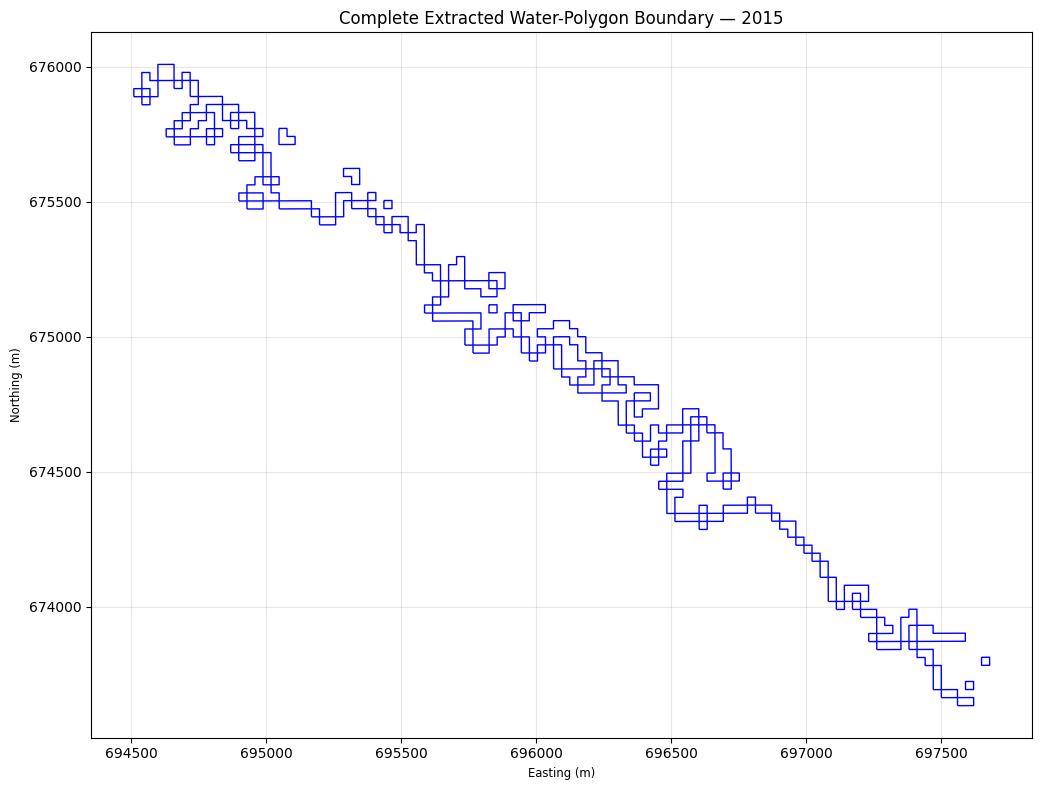

Geometry type: MultiLineString
Total boundary length: 24034.49 metres


In [37]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Load the 2015 shoreline
path_2015 = next(
    f for f in files
    if "2015" in os.path.basename(f)
)

shoreline_2015 = gpd.read_file(path_2015).to_crs("EPSG:32631")

# Combine all shoreline features
combined = shoreline_2015.geometry.union_all()

# Display the complete boundary
fig, ax = plt.subplots(figsize=(12, 8))

gpd.GeoSeries(
    [combined],
    crs=shoreline_2015.crs
).plot(ax=ax, color="blue", linewidth=1)

ax.set_title("Complete Extracted Water-Polygon Boundary — 2015")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Geometry type:", combined.geom_type)
print("Total boundary length:", round(combined.length, 2), "metres")

In [38]:
import os
import geopandas as gpd
import pandas as pd

summary = []

for path in sorted(files):
    gdf = gpd.read_file(path).to_crs("EPSG:32631")

    year = int(gdf["year"].iloc[0])

    summary.append({
        "Year": year,
        "Features": len(gdf),
        "Total length (m)": round(gdf.geometry.length.sum(), 2),
        "Min Easting": round(gdf.total_bounds[0], 2),
        "Min Northing": round(gdf.total_bounds[1], 2),
        "Max Easting": round(gdf.total_bounds[2], 2),
        "Max Northing": round(gdf.total_bounds[3], 2)
    })

summary_df = pd.DataFrame(summary).sort_values("Year")

print(summary_df.to_string(index=False))

 Year  Features  Total length (m)  Min Easting  Min Northing  Max Easting  Max Northing
 2015         7          24034.49    694508.85     673633.27    697678.23     676008.12
 2016         1          13478.40    694746.44     673573.16    697499.33     676306.75
 2017        25          42462.74    694449.97     673572.87    698362.73     676164.70
 2018        17          30117.64    694449.97     673482.67    697975.29     676067.54
 2025        10          15744.89    694924.75     673633.07    697970.93     676876.08


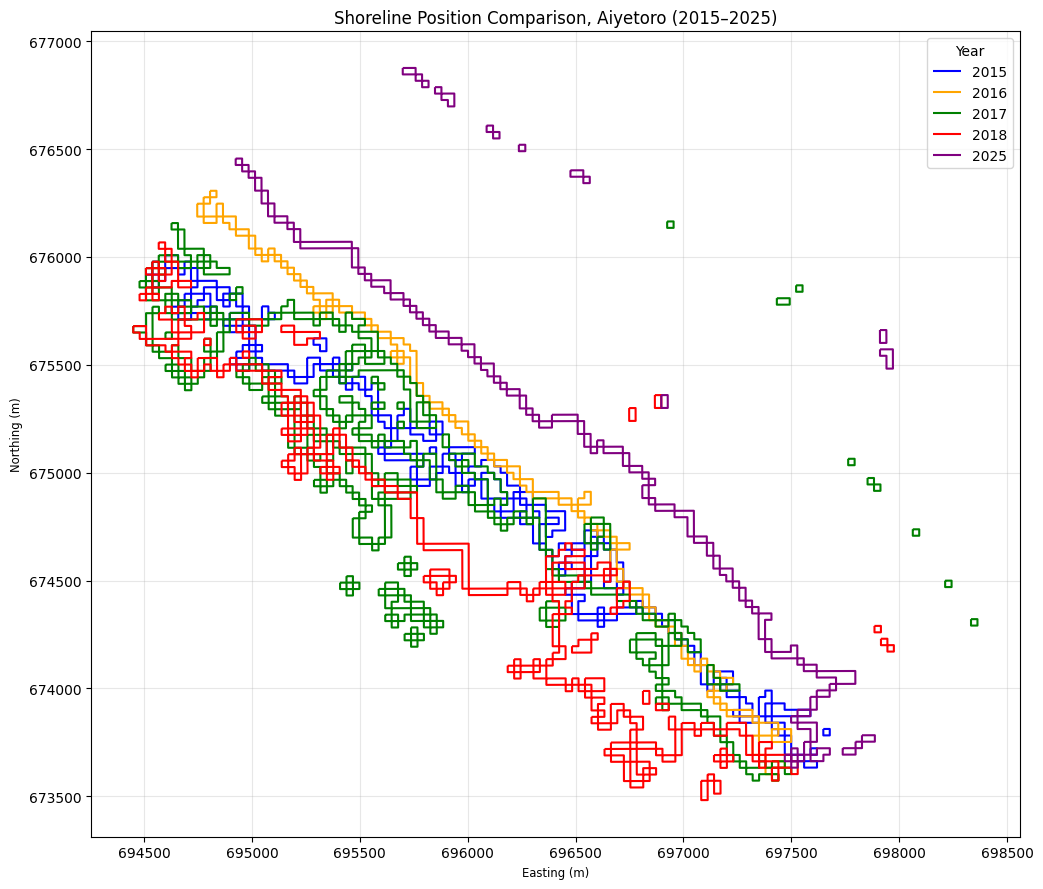

In [39]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt

year_colors = {
    2015: "blue",
    2016: "orange",
    2017: "green",
    2018: "red",
    2025: "purple"
}

fig, ax = plt.subplots(figsize=(12, 9))

for path in sorted(files):
    gdf = gpd.read_file(path).to_crs("EPSG:32631")
    year = int(gdf["year"].iloc[0])

    gdf.plot(
        ax=ax,
        color=year_colors[year],
        linewidth=1.5,
        label=str(year)
    )

ax.set_title("Shoreline Position Comparison, Aiyetoro (2015–2025)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
import geopandas as gpd
import pandas as pd

# Load the shoreline files
shorelines = {}

for path in files:
    gdf = gpd.read_file(path).to_crs("EPSG:32631")
    year = int(gdf["year"].iloc[0])
    shorelines[year] = gdf.geometry.union_all()

# Compare the spatial extents of the shorelines
extent_results = []

for year, geom in sorted(shorelines.items()):
    minx, miny, maxx, maxy = geom.bounds

    extent_results.append({
        "Year": year,
        "West-East extent (m)": round(maxx - minx, 2),
        "South-North extent (m)": round(maxy - miny, 2)
    })

extent_df = pd.DataFrame(extent_results)

print(extent_df.to_string(index=False))

 Year  West-East extent (m)  South-North extent (m)
 2015               3169.38                 2374.86
 2016               2752.89                 2733.59
 2017               3912.77                 2591.83
 2018               3525.32                 2584.87
 2025               3046.18                 3243.01


In [43]:
import geopandas as gpd
import pandas as pd

# Load the 2015 shoreline
baseline = shorelines[2015]

# Create a bounding box from the 2015 shoreline
from shapely.geometry import box

minx, miny, maxx, maxy = baseline.bounds
baseline_box = box(minx, miny, maxx, maxy)

results = []

for year, shoreline in sorted(shorelines.items()):

    minx, miny, maxx, maxy = shoreline.bounds
    current_box = box(minx, miny, maxx, maxy)

    overlap = baseline_box.intersection(current_box).area
    current_area = current_box.area

    overlap_percent = (
        overlap / current_area * 100
        if current_area > 0 else 0
    )

    results.append({
        "Year": year,
        "Bounding box overlap with 2015 (%)": round(overlap_percent, 2)
    })

overlap_df = pd.DataFrame(results)
print(overlap_df.to_string(index=False))

 Year  Bounding box overlap with 2015 (%)
 2015                              100.00
 2016                               86.88
 2017                               74.22
 2018                               82.60
 2025                               66.19


In [44]:
import geopandas as gpd
import pandas as pd
import numpy as np

# Use the shorelines already loaded in your notebook
baseline = shorelines[2015]

results = []

for year in [2016, 2017, 2018, 2025]:

    current = shorelines[year]

    # Sample points along the current shoreline every 20 metres
    distances_along = np.arange(0, current.length, 20)

    sampled_points = [
        current.interpolate(distance)
        for distance in distances_along
    ]

    # Measure distance to the nearest point on the 2015 shoreline
    distances = [
        point.distance(baseline)
        for point in sampled_points
    ]

    results.append({
        "Year": year,
        "Sample points": len(distances),
        "Mean distance from 2015 (m)": round(
            np.mean(distances), 2
        ),
        "Median distance from 2015 (m)": round(
            np.median(distances), 2
        ),
        "Maximum distance from 2015 (m)": round(
            np.max(distances), 2
        )
    })

distance_df = pd.DataFrame(results)

print(distance_df.to_string(index=False))

 Year  Sample points  Mean distance from 2015 (m)  Median distance from 2015 (m)  Maximum distance from 2015 (m)
 2016            674                        97.17                          60.04                          347.35
 2017           2124                       154.16                          78.84                         1476.48
 2018           1506                       190.82                         158.80                          691.24
 2025            788                       413.67                         338.87                         1609.79


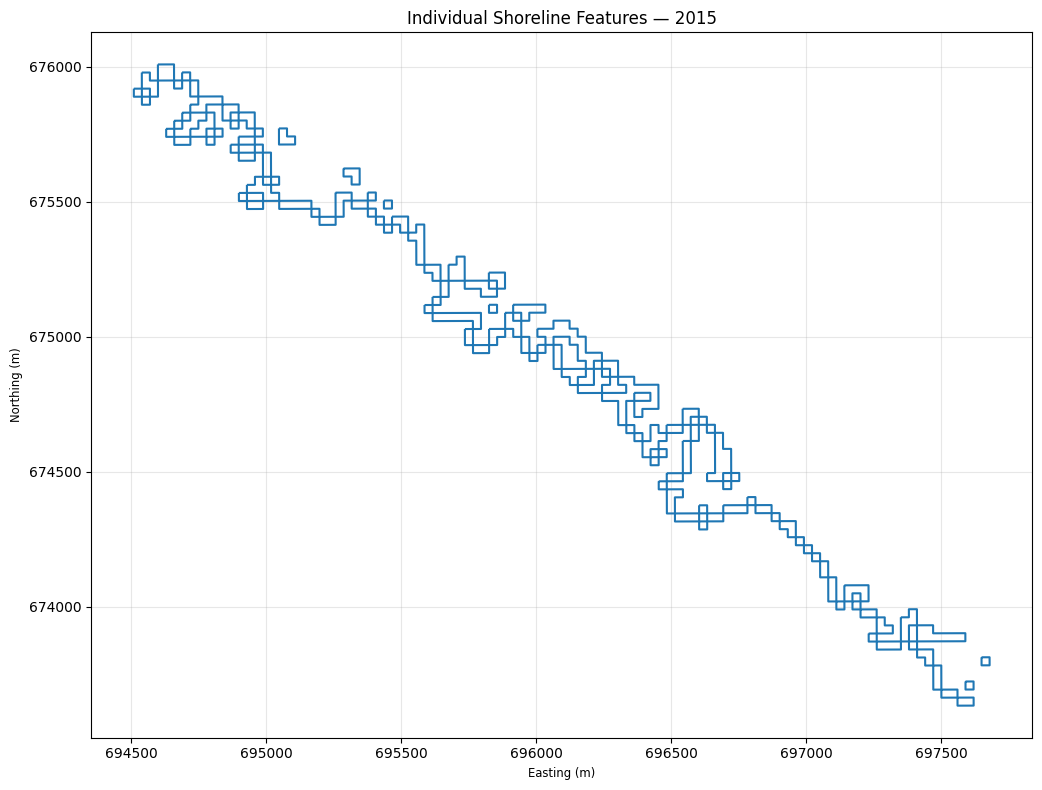

Number of shoreline features: 7


In [45]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Load the original 2015 shoreline
baseline_gdf = gpd.read_file(
    next(f for f in files if "2015" in f)
).to_crs("EPSG:32631")

# Plot individual shoreline features separately
fig, ax = plt.subplots(figsize=(12, 8))

for index, row in baseline_gdf.iterrows():
    single_feature = gpd.GeoDataFrame(
        [row],
        geometry="geometry",
        crs=baseline_gdf.crs
    )

    single_feature.plot(
        ax=ax,
        linewidth=1.5,
        label=f"Feature {index + 1}"
    )

ax.set_title("Individual Shoreline Features — 2015")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Number of shoreline features:", len(baseline_gdf))

In [46]:
import geopandas as gpd
import pandas as pd

baseline_gdf = gpd.read_file(
    next(f for f in files if "2015" in f)
).to_crs("EPSG:32631")

feature_details = []

for index, row in baseline_gdf.iterrows():
    geom = row.geometry

    feature_details.append({
        "Feature_ID": index + 1,
        "Length_m": round(geom.length, 2),
        "Min_Easting": round(geom.bounds[0], 2),
        "Min_Northing": round(geom.bounds[1], 2),
        "Max_Easting": round(geom.bounds[2], 2),
        "Max_Northing": round(geom.bounds[3], 2)
    })

feature_table = pd.DataFrame(feature_details)

print(feature_table.to_string(index=False))

 Feature_ID  Length_m  Min_Easting  Min_Northing  Max_Easting  Max_Northing
          1  23080.28    694508.85     673633.27    697619.06     676008.12
          2    238.55    695046.33     675711.35    695106.19     675771.05
          3    238.55    695285.48     675563.20    695345.34     675622.91
          4    119.28    695435.03     675474.18    695464.96     675504.08
          5    119.28    695824.13     675087.99    695854.06     675117.90
          6    119.28    697588.93     673692.98    697618.86     673722.88
          7    119.28    697648.30     673782.59    697678.23     673812.49


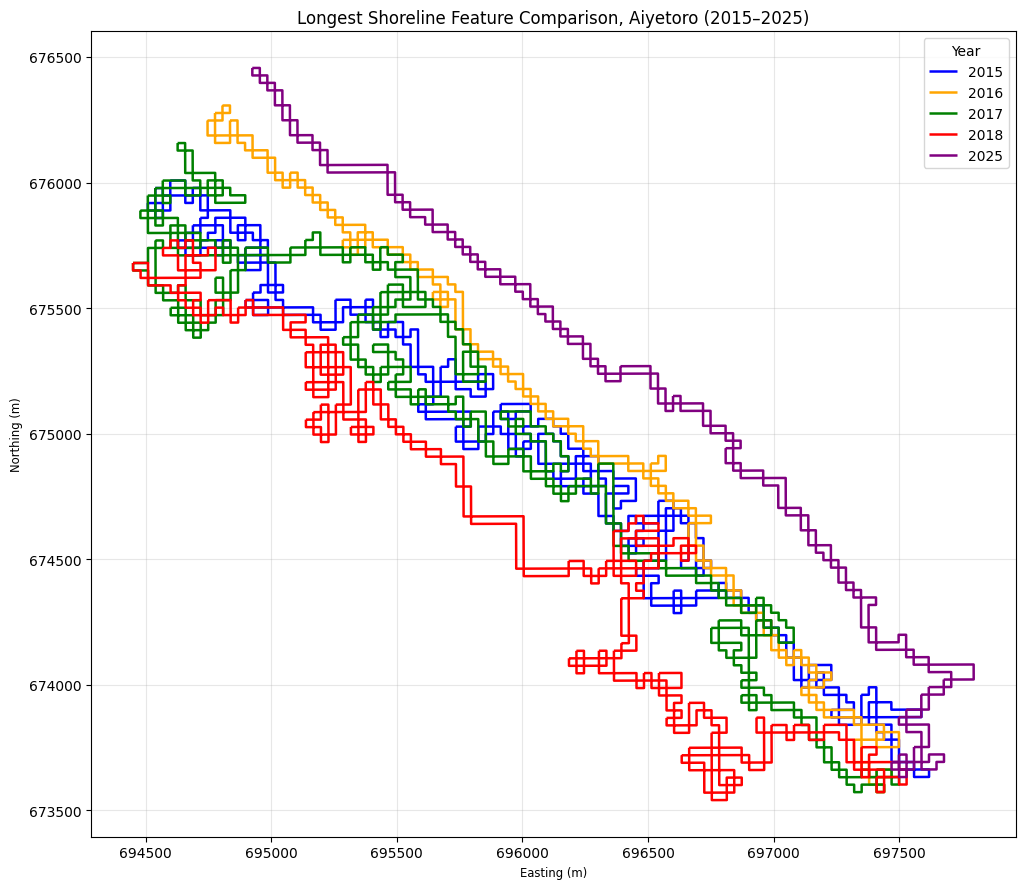

In [47]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt

years = [2015, 2016, 2017, 2018, 2025]

colors = {
    2015: "blue",
    2016: "orange",
    2017: "green",
    2018: "red",
    2025: "purple"
}

fig, ax = plt.subplots(figsize=(12, 9))

for year in years:
    path = next(
        f for f in files
        if str(year) in os.path.basename(f)
    )

    gdf = gpd.read_file(path).to_crs("EPSG:32631")

    # Select the longest individual feature
    main_feature = gdf.loc[gdf.geometry.length.idxmax()]

    main_gdf = gpd.GeoDataFrame(
        [main_feature],
        geometry="geometry",
        crs=gdf.crs
    )

    main_gdf.plot(
        ax=ax,
        color=colors[year],
        linewidth=1.8,
        label=str(year)
    )

ax.set_title("Longest Shoreline Feature Comparison, Aiyetoro (2015–2025)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [48]:
import os
import geopandas as gpd
import pandas as pd
import numpy as np

# Load the longest 2015 shoreline feature
path_2015 = next(
    f for f in files
    if "2015" in os.path.basename(f)
)

gdf_2015 = gpd.read_file(path_2015).to_crs("EPSG:32631")
baseline = gdf_2015.geometry.loc[gdf_2015.geometry.length.idxmax()]

results = []

for year in [2016, 2017, 2018, 2025]:

    path = next(
        f for f in files
        if str(year) in os.path.basename(f)
    )

    gdf = gpd.read_file(path).to_crs("EPSG:32631")

    # Select the longest feature for this year
    current = gdf.geometry.loc[gdf.geometry.length.idxmax()]

    # Sample points every 20 metres along the current feature
    distances_along = np.arange(0, current.length, 20)

    points = [
        current.interpolate(d)
        for d in distances_along
    ]

    # Distance from each point to the nearest point on 2015
    distances = np.array([
        point.distance(baseline)
        for point in points
    ])

    results.append({
        "Year": year,
        "Sample points": len(distances),
        "Mean separation (m)": round(distances.mean(), 2),
        "Median separation (m)": round(np.median(distances), 2),
        "Maximum separation (m)": round(distances.max(), 2)
    })

result_df = pd.DataFrame(results)

print(result_df.to_string(index=False))

 Year  Sample points  Mean separation (m)  Median separation (m)  Maximum separation (m)
 2016            674               106.87                  60.04                  347.35
 2017           1286                70.42                  47.43                  266.71
 2018           1160               196.58                 174.02                  570.19
 2025            660               293.93                 329.70                  538.08


In [50]:
import os
import geopandas as gpd
import pandas as pd

feature_results = []

for path in sorted(files):
    gdf = gpd.read_file(path).to_crs("EPSG:32631")
    year = int(gdf["year"].iloc[0])

    for index, geom in enumerate(gdf.geometry, start=1):
        feature_results.append({
            "Year": year,
            "Feature_ID": index,
            "Length_m": round(geom.length, 2),
            "Min_Easting": round(geom.bounds[0], 2),
            "Min_Northing": round(geom.bounds[1], 2),
            "Max_Easting": round(geom.bounds[2], 2),
            "Max_Northing": round(geom.bounds[3], 2)
        })

feature_df = pd.DataFrame(feature_results)

print("Total shoreline features:", len(feature_df))
print("\nFeatures per year:")
print(feature_df.groupby("Year").size())

print("\nLongest features per year:")
print(
    feature_df.loc[
        feature_df.groupby("Year")["Length_m"].idxmax()
    ].sort_values("Year").to_string(index=False)
)

Total shoreline features: 60

Features per year:
Year
2015     7
2016     1
2017    25
2018    17
2025    10
dtype: int64

Longest features per year:
 Year  Feature_ID  Length_m  Min_Easting  Min_Northing  Max_Easting  Max_Northing
 2015           1  23080.28    694508.85     673633.27    697619.06     676008.12
 2016           1  13478.40    694746.44     673573.16    697499.33     676306.75
 2017           2  25704.40    694449.97     673572.87    697499.82     676157.14
 2018           2  23199.62    694449.97     673541.19    697529.65     675769.78
 2025           1  13180.43    694924.75     673633.07    697796.78     676456.17


In [51]:
import pandas as pd

# Use the preliminary distance results already obtained
results = pd.DataFrame({
    "Year": [2016, 2017, 2018, 2025],
    "Mean_Separation_m": [106.87, 70.42, 196.58, 293.93],
    "Median_Separation_m": [60.04, 47.43, 174.02, 329.70]
})

results["Years_From_Baseline"] = results["Year"] - 2015

results["Mean_Separation_m_per_year"] = (
    results["Mean_Separation_m"] /
    results["Years_From_Baseline"]
)

print(results.round(2).to_string(index=False))

 Year  Mean_Separation_m  Median_Separation_m  Years_From_Baseline  Mean_Separation_m_per_year
 2016             106.87                60.04                    1                      106.87
 2017              70.42                47.43                    2                       35.21
 2018             196.58               174.02                    3                       65.53
 2025             293.93               329.70                   10                       29.39


PRELIMINARY SHORELINE SEPARATION RESULTS


,Year,Mean_Separation_m,Median_Separation_m
0,2016,106.87,60.04
1,2017,70.42,47.43
2,2018,196.58,174.02
3,2025,293.93,329.70


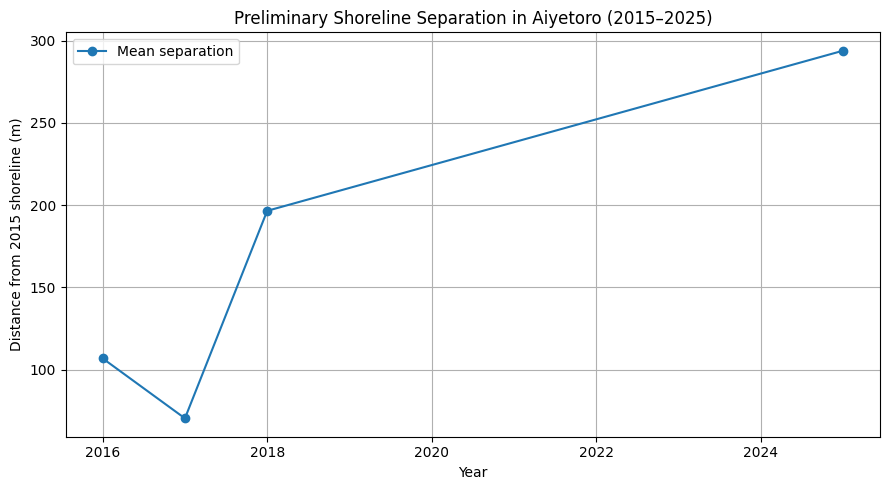

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

# Preliminary shoreline separation from the 2015 baseline
data = {
    "Year": [2016, 2017, 2018, 2025],
    "Mean_Separation_m": [106.87, 70.42, 196.58, 293.93],
    "Median_Separation_m": [60.04, 47.43, 174.02, 329.70]
}

df = pd.DataFrame(data)

print("PRELIMINARY SHORELINE SEPARATION RESULTS")
display(df.round(2))

# Plot the mean separation
plt.figure(figsize=(9, 5))
plt.plot(
    df["Year"],
    df["Mean_Separation_m"],
    marker="o",
    label="Mean separation"
)
plt.xlabel("Year")
plt.ylabel("Distance from 2015 shoreline (m)")
plt.title("Preliminary Shoreline Separation in Aiyetoro (2015–2025)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [53]:
import pandas as pd

results = pd.DataFrame({
    "Year": [2016, 2017, 2018, 2025],
    "Mean_Separation_m": [106.87, 70.42, 196.58, 293.93],
    "Median_Separation_m": [60.04, 47.43, 174.02, 329.70]
})

results.to_csv("Aiyetoro_Shoreline_Results.csv", index=False)

from google.colab import files
files.download("Aiyetoro_Shoreline_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
!pip install -q xgboost shap

In [55]:
import xgboost as xgb
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("XGBoost version:", xgb.__version__)
print("SHAP version:", shap.__version__)

print("XGBoost and SHAP are ready!")


XGBoost version: 3.4.1
SHAP version: 0.54.1
XGBoost and SHAP are ready!


In [56]:
print("Available shoreline files:")

import os

for file in os.listdir("/content"):
    if file.endswith(".gpkg") or file.endswith(".csv"):
        print(file)

Available shoreline files:
Shoreline_2018_Metres.gpkg
Shoreline_2025_Metres.gpkg..gpkg
Shoreline_2016_Metres.gpkg
Shoreline_2015_Metres.gpkg..gpkg
Shoreline_2017_Metres.gpkg
Aiyetoro_Shoreline_Results.csv


In [57]:
import os

print("SHORELINE FILES AVAILABLE IN COLAB:\n")

for file in os.listdir("/content"):
    if file.endswith((".gpkg", ".csv", ".shp", ".geojson")):
        print(file)


SHORELINE FILES AVAILABLE IN COLAB:

Shoreline_2018_Metres.gpkg
Shoreline_2025_Metres.gpkg..gpkg
Shoreline_2016_Metres.gpkg
Shoreline_2015_Metres.gpkg..gpkg
Shoreline_2017_Metres.gpkg
Aiyetoro_Shoreline_Results.csv


In [59]:
import os
import geopandas as gpd
import pandas as pd

# Your five shoreline files
shoreline_files = {
    2015: "/content/Shoreline_2015_Metres.gpkg..gpkg",
    2016: "/content/Shoreline_2016_Metres.gpkg",
    2017: "/content/Shoreline_2017_Metres.gpkg",
    2018: "/content/Shoreline_2018_Metres.gpkg",
    2025: "/content/Shoreline_2025_Metres.gpkg..gpkg"
}

# Load the results CSV
results = pd.read_csv("/content/Aiyetoro_Shoreline_Results.csv")

print("=== EXISTING RESULTS CSV ===")
display(results)

print("\n=== SHORELINE DATA SUMMARY ===")

shorelines = {}

for year, path in shoreline_files.items():
    gdf = gpd.read_file(path)
    shorelines[year] = gdf

    print(f"\nYear: {year}")
    print("Features:", len(gdf))
    print("CRS:", gdf.crs)
    print("Columns:", list(gdf.columns))
    print("Geometry types:", gdf.geom_type.value_counts().to_dict())

print("\nInspection complete.")

=== EXISTING RESULTS CSV ===


,Year,Mean_Separation_m,Median_Separation_m
0,2016,106.87,60.04
1,2017,70.42,47.43
2,2018,196.58,174.02
3,2025,293.93,329.70



=== SHORELINE DATA SUMMARY ===

Year: 2015
Features: 7
CRS: EPSG:32631
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']
Geometry types: {'MultiLineString': 7}

Year: 2016
Features: 1
CRS: EPSG:32631
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']
Geometry types: {'MultiLineString': 1}

Year: 2017
Features: 25
CRS: EPSG:32631
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']
Geometry types: {'MultiLineString': 25}

Year: 2018
Features: 17
CRS: EPSG:32631
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']
Geometry types: {'MultiLineString': 17}

Year: 2025
Features: 10
CRS: EPSG:32631
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']
Geometry types: {'MultiLineString': 10}

Inspection complete.


In [60]:
import geopandas as gpd
import pandas as pd
import numpy as np
import os

# Load the shoreline files
shoreline_files = {
    2015: "/content/Shoreline_2015_Metres.gpkg..gpkg",
    2016: "/content/Shoreline_2016_Metres.gpkg",
    2017: "/content/Shoreline_2017_Metres.gpkg",
    2018: "/content/Shoreline_2018_Metres.gpkg",
    2025: "/content/Shoreline_2025_Metres.gpkg..gpkg"
}

shorelines = {}

for year, path in shoreline_files.items():
    if os.path.exists(path):
        gdf = gpd.read_file(path)
        gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
        shorelines[year] = gdf
        print(f"{year}: {len(gdf)} valid shoreline features loaded")
    else:
        print(f"FILE NOT FOUND: {path}")

# Inspect the available data
print("\nAvailable columns:")
for year, gdf in shorelines.items():
    print(year, list(gdf.columns))

print("\nCoordinate reference systems:")
for year, gdf in shorelines.items():
    print(year, gdf.crs)

print("\nData preparation inspection complete.")

2015: 7 valid shoreline features loaded
2016: 1 valid shoreline features loaded
2017: 25 valid shoreline features loaded
2018: 17 valid shoreline features loaded
2025: 10 valid shoreline features loaded

Available columns:
2015 ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']
2016 ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']
2017 ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']
2018 ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']
2025 ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']

Coordinate reference systems:
2015 EPSG:32631
2016 EPSG:32631
2017 EPSG:32631
2018 EPSG:32631
2025 EPSG:32631

Data preparation inspection complete.


In [61]:
import geopandas as gpd
import pandas as pd
import numpy as np
import os

# Load the shoreline files
shoreline_files = {
    2015: "/content/Shoreline_2015_Metres.gpkg..gpkg",
    2016: "/content/Shoreline_2016_Metres.gpkg",
    2017: "/content/Shoreline_2017_Metres.gpkg",
    2018: "/content/Shoreline_2018_Metres.gpkg",
    2025: "/content/Shoreline_2025_Metres.gpkg..gpkg"
}

shorelines = {}

for year, path in shoreline_files.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing file: {path}")

    gdf = gpd.read_file(path)
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()

    if gdf.crs is None:
        raise ValueError(f"CRS missing for {year}")

    # Use a metric CRS for distance calculations
    gdf = gdf.to_crs(epsg=32631)
    shorelines[year] = gdf

    print(f"{year}: {len(gdf)} features loaded")

# Combine each year's shoreline geometry
annual_lines = {}

for year, gdf in shorelines.items():
    annual_lines[year] = gdf.geometry.union_all()

# Compare each year with the 2015 reference
reference = annual_lines[2015]

records = []

for year, geometry in annual_lines.items():
    if year == 2015:
        continue

    distance = geometry.distance(reference)

    records.append({
        "Year": year,
        "Years_since_2015": year - 2015,
        "Minimum_separation_m": distance
    })

distance_table = pd.DataFrame(records)

print("\nPRELIMINARY SHORELINE SEPARATION")
display(distance_table)

distance_table.to_csv(
    "/content/Preliminary_Shoreline_Separation.csv",
    index=False
)

print("Saved: Preliminary_Shoreline_Separation.csv")

2015: 7 features loaded
2016: 1 features loaded
2017: 25 features loaded
2018: 17 features loaded
2025: 10 features loaded

PRELIMINARY SHORELINE SEPARATION


,Year,Years_since_2015,Minimum_separation_m
0,2016,1,0.0
1,2017,2,0.0
2,2018,3,0.0
3,2025,10,0.0


Saved: Preliminary_Shoreline_Separation.csv


In [63]:
import geopandas as gpd
import pandas as pd
import numpy as np
import os

# Combine the 2015 shoreline features into one reference geometry
reference = shorelines[2015].geometry.union_all()

results = []

for year in [2016, 2017, 2018, 2025]:
    gdf = shorelines[year]

    # Combine the shoreline features for this year
    current = gdf.geometry.union_all()

    # Sample points along each line at 30 m intervals
    points = []

    for geom in gdf.geometry:
        if geom.geom_type == "LineString":
            lines = [geom]
        elif geom.geom_type == "MultiLineString":
            lines = list(geom.geoms)
        else:
            continue

        for line in lines:
            distances = np.arange(0, line.length, 30)

            for d in distances:
                points.append(line.interpolate(float(d)))

            # Include the endpoint
            points.append(line.interpolate(line.length))

    if not points:
        print(f"No usable line points for {year}")
        continue

    # Measure each sampled point's distance to the 2015 reference
    distances_m = np.array([
        point.distance(reference) for point in points
    ])

    results.append({
        "Year": year,
        "Years_since_2015": year - 2015,
        "Sample_points": len(distances_m),
        "Mean_separation_m": distances_m.mean(),
        "Median_separation_m": np.median(distances_m),
        "P95_separation_m": np.percentile(distances_m, 95)
    })

separation_table = pd.DataFrame(results)

display(separation_table)

separation_table.to_csv(
    "/content/Shoreline_Separation_Sampled.csv",
    index=False
)

print("Saved: Shoreline_Separation_Sampled.csv")

,Year,Years_since_2015,Sample_points,Mean_separation_m,Median_separation_m,P95_separation_m
0,2016,1,533,95.355470,59.666971,253.665281
1,2017,2,1651,159.479235,84.342556,617.817712
2,2018,3,1163,196.500166,168.679953,485.197395
3,2025,10,616,413.141110,336.371420,1283.309763


Saved: Shoreline_Separation_Sampled.csv


In [64]:
# Inspect available predictor variables in each shoreline file

for year, gdf in shorelines.items():
    print(f"\n{'='*40}")
    print(f"YEAR: {year}")
    print(f"{'='*40}")

    print("Columns:", list(gdf.columns))
    display(gdf.drop(columns="geometry").head(3))

# Inspect the preliminary separation results
print("\nPRELIMINARY SEPARATION DATA")
display(separation_table.describe())


YEAR: 2015
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']


,ndwi_thres,year,shoreline,count
0,0,2015,1,287
1,0,2015,1,3
2,0,2015,1,3



YEAR: 2016
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']


,ndwi_thres,year,shoreline,count
0,0,2016,1,147



YEAR: 2017
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']


...

,ndwi_thres,year,shoreline,count
0,0,2018,1,19
1,0,2018,1,279
2,0,2018,1,1



YEAR: 2025
Columns: ['ndwi_thres', 'year', 'shoreline', 'count', 'geometry']


,ndwi_thres,year,shoreline,count
0,0,2025,1,151
1,0,2025,1,4
2,0,2025,1,4



PRELIMINARY SEPARATION DATA


,Year,Years_since_2015,Sample_points,Mean_separation_m,Median_separation_m,P95_separation_m
count,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000
mean,2019.000000,4.000000,990.750000,216.118996,162.265225,659.997538
std,4.082483,4.082483,521.399639,137.833842,125.103237,441.949567
min,2016.000000,1.000000,533.000000,95.355470,59.666971,253.665281
25%,2016.750000,1.750000,595.250000,143.448294,78.173660,427.314367
50%,2017.500000,2.500000,889.500000,177.989701,126.511255,551.507554
75%,2019.750000,4.750000,1285.000000,250.660402,210.602820,784.190724
max,2025.000000,10.000000,1651.000000,413.141110,336.371420,1283.309763


In [65]:
import geopandas as gpd
import pandas as pd

# Calculate shoreline length for each year
shoreline_lengths = []

for year, gdf in shorelines.items():

    # Ensure coordinates use a projected CRS in metres
    gdf = gdf.to_crs(epsg=32631)

    # Combine the extracted shoreline features
    combined_line = gdf.geometry.union_all()

    # Calculate total length in metres and kilometres
    length_m = combined_line.length
    length_km = length_m / 1000

    shoreline_lengths.append({
        "Year": year,
        "Total_Shoreline_Length_m": round(length_m, 2),
        "Total_Shoreline_Length_km": round(length_km, 3),
        "Number_of_Features": len(gdf)
    })

# Create and display the results table
shoreline_length_table = pd.DataFrame(shoreline_lengths)

display(shoreline_length_table)

# Save the results
shoreline_length_table.to_csv(
    "/content/Aiyetoro_Shoreline_Lengths.csv",
    index=False
)

print("Shoreline length results saved successfully.")

,Year,Total_Shoreline_Length_m,Total_Shoreline_Length_km,Number_of_Features
0,2015,24034.49,24.034,7
1,2016,13478.40,13.478,1
2,2017,42462.74,42.463,25
3,2018,30117.64,30.118,17
4,2025,15744.89,15.745,10


Shoreline length results saved successfully.


In [66]:
import geopandas as gpd
import pandas as pd

geometry_check = []

for year, gdf in shorelines.items():

    gdf = gdf.to_crs(epsg=32631)

    # Count empty and invalid geometries
    empty_count = gdf.geometry.is_empty.sum()
    invalid_count = (~gdf.geometry.is_valid).sum()

    # Count geometry types
    geometry_types = gdf.geom_type.value_counts().to_dict()

    # Calculate individual feature lengths
    lengths_km = gdf.geometry.length / 1000

    geometry_check.append({
        "Year": year,
        "Feature_Count": len(gdf),
        "Empty_Geometries": int(empty_count),
        "Invalid_Geometries": int(invalid_count),
        "Shortest_Feature_km": round(lengths_km.min(), 3),
        "Longest_Feature_km": round(lengths_km.max(), 3),
        "Mean_Feature_Length_km": round(lengths_km.mean(), 3),
        "Geometry_Types": str(geometry_types)
    })

geometry_check_df = pd.DataFrame(geometry_check)

display(geometry_check_df)

geometry_check_df.to_csv(
    "/content/Aiyetoro_Geometry_Quality_Check.csv",
    index=False
)

print("Geometry quality check completed.")

,Year,Feature_Count,Empty_Geometries,Invalid_Geometries,Shortest_Feature_km,Longest_Feature_km,Mean_Feature_Length_km,Geometry_Types
0,2015,7,0,0,0.119,23.080,3.433,{'MultiLineString': 7}
1,2016,1,0,0,13.478,13.478,13.478,{'MultiLineString': 1}
2,2017,25,0,0,0.119,25.704,1.699,{'MultiLineString': 25}
3,2018,17,0,0,0.119,23.200,1.772,{'MultiLineString': 17}
4,2025,10,0,0,0.119,13.180,1.574,{'MultiLineString': 10}


Geometry quality check completed.


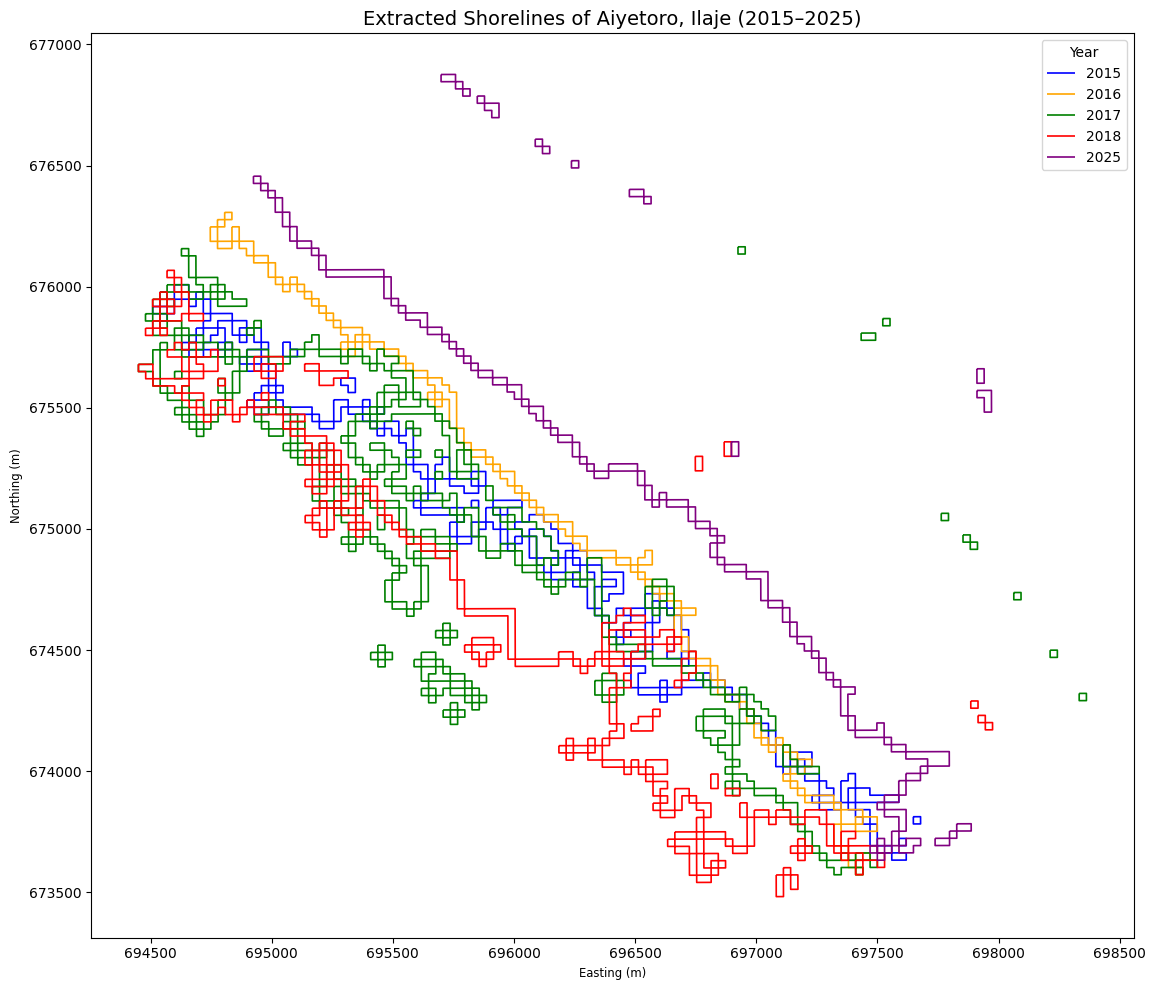

In [68]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

colors = {
    2015: "blue",
    2016: "orange",
    2017: "green",
    2018: "red",
    2025: "purple"
}

for year, gdf in shorelines.items():
    gdf = gdf.to_crs(epsg=32631)

    gdf.plot(
        ax=ax,
        color=colors.get(int(year), "gray"),
        linewidth=1.2,
        label=str(year)
    )

ax.set_title(
    "Extracted Shorelines of Aiyetoro, Ilaje (2015–2025)",
    fontsize=14
)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [70]:
# STEP 1: Prepare the preliminary modelling dataset

import pandas as pd
import numpy as np

# Load the shoreline separation results
separation = pd.read_csv(
    "/content/Shoreline_Separation_Sampled.csv"
)

# Display the available measurements
print("Available data:")
display(separation)

# Select the columns needed for preliminary analysis
model_data = separation[
    [
        "Year",
        "Years_since_2015",
        "Mean_separation_m",
        "Median_separation_m",
        "P95_separation_m"
    ]
].copy()

# Check for missing values
print("\nMissing values:")
display(model_data.isnull().sum())

# Display the dataset dimensions
print("\nDataset dimensions:", model_data.shape)

print("\nPrepared dataset:")
display(model_data)

Available data:


,Year,Years_since_2015,Sample_points,Mean_separation_m,Median_separation_m,P95_separation_m
0,2016,1,533,95.355470,59.666971,253.665281
1,2017,2,1651,159.479235,84.342556,617.817712
2,2018,3,1163,196.500166,168.679953,485.197395
3,2025,10,616,413.141110,336.371420,1283.309763



Missing values:


,0
Year,0
Years_since_2015,0
Mean_separation_m,0
Median_separation_m,0
P95_separation_m,0



Dataset dimensions: (4, 5)

Prepared dataset:


,Year,Years_since_2015,Mean_separation_m,Median_separation_m,P95_separation_m
0,2016,1,95.355470,59.666971,253.665281
1,2017,2,159.479235,84.342556,617.817712
2,2018,3,196.500166,168.679953,485.197395
3,2025,10,413.141110,336.371420,1283.309763


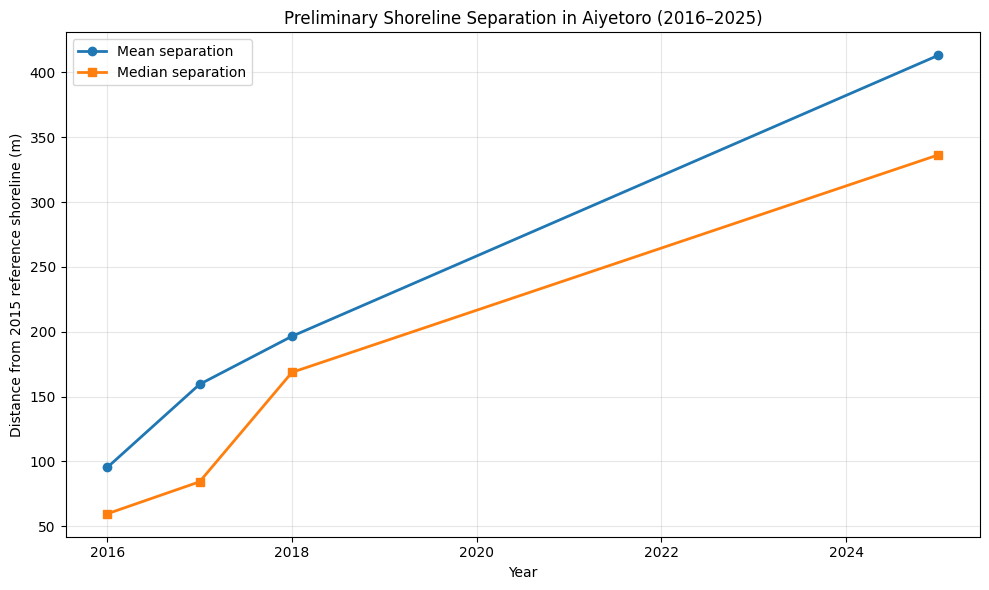

In [71]:
# STEP 2: Visualize preliminary shoreline separation

import matplotlib.pyplot as plt

# Load the existing separation dataset
separation = pd.read_csv(
    "/content/Shoreline_Separation_Sampled.csv"
)

# Sort observations by year
separation = separation.sort_values("Year")

# Plot mean separation
plt.figure(figsize=(10, 6))

plt.plot(
    separation["Year"],
    separation["Mean_separation_m"],
    marker="o",
    linewidth=2,
    label="Mean separation"
)

plt.plot(
    separation["Year"],
    separation["Median_separation_m"],
    marker="s",
    linewidth=2,
    label="Median separation"
)

plt.xlabel("Year")
plt.ylabel("Distance from 2015 reference shoreline (m)")
plt.title("Preliminary Shoreline Separation in Aiyetoro (2016–2025)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [72]:
# STEP 3: Inspect the shoreline separation sample data

import pandas as pd
import os

file_path = "/content/Shoreline_Separation_Sampled.csv"

# Load the sample data
samples = pd.read_csv(file_path)

print("Dataset shape:", samples.shape)
print("\nColumn names:")
print(samples.columns.tolist())

print("\nFirst 10 observations:")
display(samples.head(10))

print("\nData types:")
print(samples.dtypes)

print("\nSummary statistics:")
display(samples.describe())

Dataset shape: (4, 6)

Column names:
['Year', 'Years_since_2015', 'Sample_points', 'Mean_separation_m', 'Median_separation_m', 'P95_separation_m']

First 10 observations:


,Year,Years_since_2015,Sample_points,Mean_separation_m,Median_separation_m,P95_separation_m
0,2016,1,533,95.355470,59.666971,253.665281
1,2017,2,1651,159.479235,84.342556,617.817712
2,2018,3,1163,196.500166,168.679953,485.197395
3,2025,10,616,413.141110,336.371420,1283.309763



Data types:
Year                     int64
Years_since_2015         int64
Sample_points            int64
Mean_separation_m      float64
Median_separation_m    float64
P95_separation_m       float64
dtype: object

Summary statistics:


,Year,Years_since_2015,Sample_points,Mean_separation_m,Median_separation_m,P95_separation_m
count,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000
mean,2019.000000,4.000000,990.750000,216.118996,162.265225,659.997538
std,4.082483,4.082483,521.399639,137.833842,125.103237,441.949567
min,2016.000000,1.000000,533.000000,95.355470,59.666971,253.665281
25%,2016.750000,1.750000,595.250000,143.448294,78.173660,427.314367
50%,2017.500000,2.500000,889.500000,177.989701,126.511255,551.507554
75%,2019.750000,4.750000,1285.000000,250.660402,210.602820,784.190724
max,2025.000000,10.000000,1651.000000,413.141110,336.371420,1283.309763


In [73]:
# STEP 4: Inspect shoreline geometries for spatial modelling

import geopandas as gpd
import pandas as pd

for year, gdf in shorelines.items():
    gdf = gdf.to_crs(epsg=32631)

    print(f"\n{'='*40}")
    print(f"YEAR: {year}")
    print(f"{'='*40}")

    print("Number of shoreline features:", len(gdf))
    print("Geometry types:", gdf.geom_type.value_counts().to_dict())
    print("Total shoreline length (km):",
          round(gdf.geometry.length.sum() / 1000, 3))

    print("Bounds (metres):", gdf.total_bounds)


YEAR: 2015
Number of shoreline features: 7
Geometry types: {'MultiLineString': 7}
Total shoreline length (km): 24.034
Bounds (metres): [694508.85189008 673633.26668699 697678.23225578 676008.12185941]

YEAR: 2016
Number of shoreline features: 1
Geometry types: {'MultiLineString': 1}
Total shoreline length (km): 13.478
Bounds (metres): [694746.43902973 673573.16386679 697499.32689413 676306.75235806]

YEAR: 2017
Number of shoreline features: 25
Geometry types: {'MultiLineString': 25}
Total shoreline length (km): 42.463
Bounds (metres): [694449.96563223 673572.86817575 698362.73182401 676164.7023778 ]

YEAR: 2018
Number of shoreline features: 17
Geometry types: {'MultiLineString': 17}
Total shoreline length (km): 30.118
Bounds (metres): [694449.96563223 673482.6659757  697975.28766548 676067.53567009]

YEAR: 2025
Number of shoreline features: 10
Geometry types: {'MultiLineString': 10}
Total shoreline length (km): 15.745
Bounds (metres): [694924.74958329 673633.06937834 697970.93362289 6

In [74]:
# STEP 5: Generate spatial sample points and measure separation

import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import Point

# Work with projected coordinates in metres
shorelines_projected = {
    year: gdf.to_crs(epsg=32631)
    for year, gdf in shorelines.items()
}

# Combine 2015 shoreline geometries into a reference
baseline = gpd.GeoSeries(
    shorelines_projected[2015].geometry,
    crs="EPSG:32631"
).union_all()

results = []

# Sample every 100 metres along each year's extracted shoreline
spacing = 100

for year, gdf in shorelines_projected.items():

    if year == 2015:
        continue

    for feature_id, geom in enumerate(gdf.geometry):

        if geom is None or geom.is_empty:
            continue

        # Sample each component of a MultiLineString separately
        if geom.geom_type == "MultiLineString":
            lines = list(geom.geoms)
        elif geom.geom_type == "LineString":
            lines = [geom]
        else:
            continue

        for line_id, line in enumerate(lines):

            if line.length == 0:
                continue

            distances = np.arange(0, line.length, spacing)

            for distance_along in distances:

                point = line.interpolate(float(distance_along))

                results.append({
                    "Year": int(year),
                    "Feature_ID": feature_id,
                    "Line_ID": line_id,
                    "Distance_along_line_m": round(
                        float(distance_along), 2
                    ),
                    "Easting": point.x,
                    "Northing": point.y,
                    "Distance_to_2015_m": point.distance(baseline)
                })

# Create the spatial dataset
spatial_samples = pd.DataFrame(results)

# Save the output
output_path = "/content/Aiyetoro_Spatial_Samples.csv"
spatial_samples.to_csv(output_path, index=False)

print("Spatial dataset created.")
print("Dataset shape:", spatial_samples.shape)
print("\nSamples per year:")
display(spatial_samples.groupby("Year").size().rename("Sample_Count"))

print("\nFirst 10 observations:")
display(spatial_samples.head(10))

print("\nSaved to:", output_path)

Spatial dataset created.
Dataset shape: (1327, 7)

Samples per year:


,Sample_Count
Year,
2016,180
2017,555
2018,389
2025,203



First 10 observations:


,Year,Feature_ID,Line_ID,Distance_along_line_m,Easting,Northing,Distance_to_2015_m
0,2016,0,0,0.0,694806.006141,676276.850189,306.925278
1,2016,0,0,100.0,694825.280308,676276.913299,316.740671
2,2016,0,1,0.0,696511.176100,674851.815406,66.696865
3,2016,0,1,100.0,696551.369646,674911.557974,134.187960
4,2016,0,1,200.0,696549.729216,674851.942485,102.642826
5,2016,0,2,0.0,697410.415960,673573.163867,126.513890
6,2016,0,2,100.0,697429.694292,673573.227576,113.694692
7,2016,0,3,0.0,697410.218973,673632.773527,84.342556
8,2016,0,3,100.0,697469.823323,673652.249013,31.636835
9,2016,0,4,0.0,694746.634118,676187.241448,199.973015



Saved to: /content/Aiyetoro_Spatial_Samples.csv


In [75]:
# STEP 6: Inspect spatial samples before modelling

import pandas as pd
import numpy as np

# Load the spatial sample dataset
spatial_samples = pd.read_csv(
    "/content/Aiyetoro_Spatial_Samples.csv"
)

# Summarize distances by year
distance_summary = (
    spatial_samples
    .groupby("Year")["Distance_to_2015_m"]
    .agg(
        Sample_Count="count",
        Mean_Distance="mean",
        Median_Distance="median",
        Maximum_Distance="max",
        Minimum_Distance="min"
    )
    .round(2)
)

print("Distance summary by year:")
display(distance_summary)

# Calculate the overall 95th percentile
p95 = spatial_samples["Distance_to_2015_m"].quantile(0.95)

# Flag large distances for inspection
spatial_samples["Flag_P95"] = (
    spatial_samples["Distance_to_2015_m"] > p95
)

print(f"\nOverall 95th-percentile distance: {p95:.2f} m")

print("\nNumber of points flagged for inspection:")
print(spatial_samples["Flag_P95"].sum())

print("\nFlagged points by year:")
display(
    spatial_samples.groupby("Year")["Flag_P95"]
    .sum()
    .rename("Flagged_Points")
    .to_frame()
)

# Save the inspected dataset
spatial_samples.to_csv(
    "/content/Aiyetoro_Spatial_Samples_Inspected.csv",
    index=False
)

print("\nSaved: /content/Aiyetoro_Spatial_Samples_Inspected.csv")

Distance summary by year:


,Sample_Count,Mean_Distance,Median_Distance,Maximum_Distance,Minimum_Distance
Year,,,,,
2016,180,93.72,59.67,316.74,0.0
2017,555,170.88,84.38,1451.71,0.0
2018,389,203.28,178.83,683.85,0.0
2025,203,413.06,329.98,1604.88,0.0



Overall 95th-percentile distance: 606.65 m

Number of points flagged for inspection:
67

Flagged points by year:


,Flagged_Points
Year,
2016,0
2017,37
2018,2
2025,28



Saved: /content/Aiyetoro_Spatial_Samples_Inspected.csv


Total flagged points: 67


,Year,Feature_ID,Line_ID,Distance_along_line_m,Easting,Northing,Distance_to_2015_m
1323,2025,8,0,100.0,697940.541221,675650.728500,1604.884257
1325,2025,9,0,100.0,697970.770498,675531.636221,1557.710676
1322,2025,8,0,0.0,697910.871126,675601.576016,1551.065730
1324,2025,9,0,0.0,697910.970163,675571.771095,1532.918906
1326,2025,9,0,200.0,697941.030369,675503.540087,1517.272610
722,2017,19,0,100.0,697541.526158,675838.791444,1451.714210
721,2017,19,0,0.0,697522.249982,675838.727490,1439.252387
720,2017,18,0,100.0,697492.550820,675798.294975,1389.181127
712,2017,16,0,100.0,696943.881389,676134.862653,1353.337134
711,2017,16,0,0.0,696924.605853,676134.798866,1341.676804


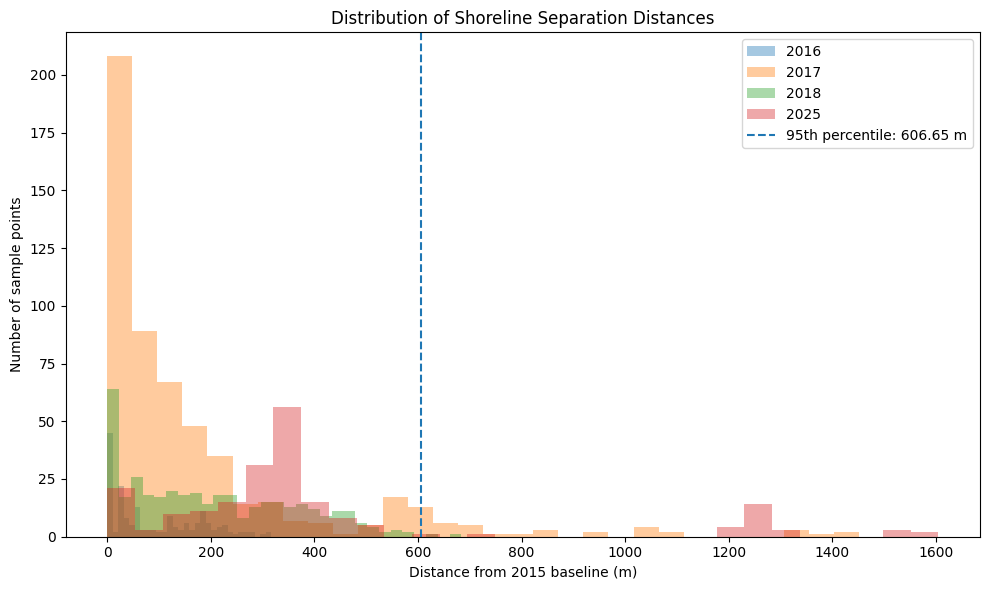

In [76]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the inspected spatial samples
df = pd.read_csv(
    "/content/Aiyetoro_Spatial_Samples_Inspected.csv"
)

# Display the 67 points flagged for inspection
flagged = df[df["Flag_P95"] == True].copy()

print("Total flagged points:", len(flagged))

display(
    flagged[
        [
            "Year",
            "Feature_ID",
            "Line_ID",
            "Distance_along_line_m",
            "Easting",
            "Northing",
            "Distance_to_2015_m"
        ]
    ].sort_values(
        "Distance_to_2015_m",
        ascending=False
    ).head(20)
)

# Plot the distance distribution by year
plt.figure(figsize=(10, 6))

for year in sorted(df["Year"].unique()):
    distances = df.loc[
        df["Year"] == year,
        "Distance_to_2015_m"
    ]
    plt.hist(
        distances,
        bins=30,
        alpha=0.4,
        label=str(year)
    )

plt.axvline(
    606.65,
    linestyle="--",
    label="95th percentile: 606.65 m"
)

plt.xlabel("Distance from 2015 baseline (m)")
plt.ylabel("Number of sample points")
plt.title("Distribution of Shoreline Separation Distances")
plt.legend()
plt.tight_layout()
plt.show()

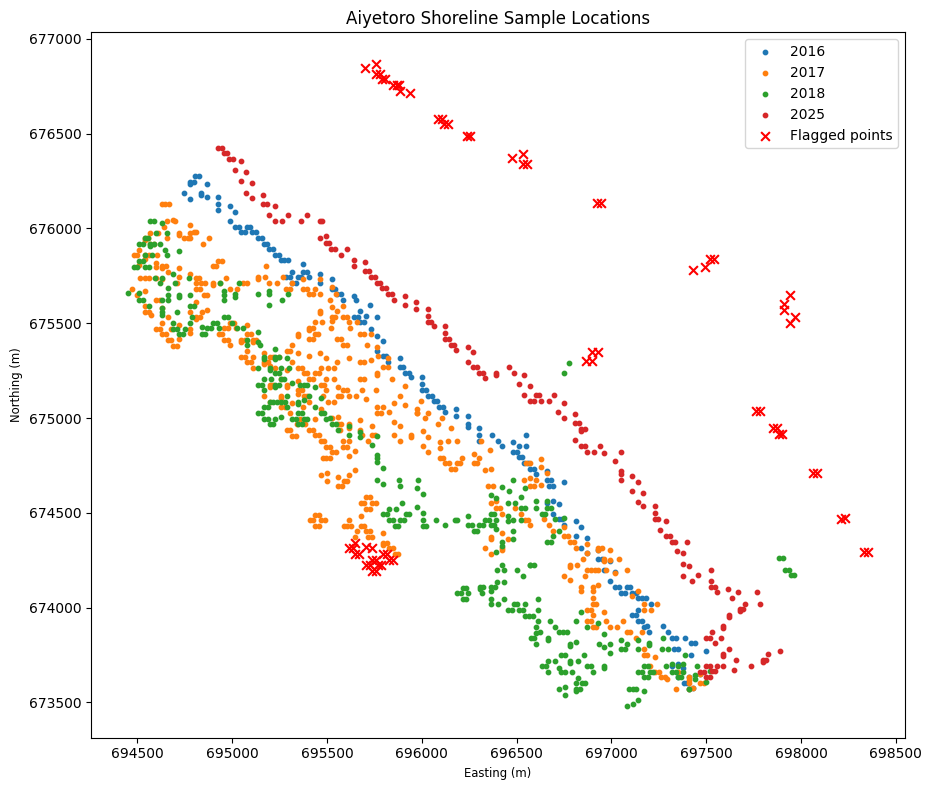

In [81]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/Aiyetoro_Spatial_Samples_Inspected.csv")

normal = df[df["Flag_P95"] == False].copy()
flagged = df[df["Flag_P95"] == True].copy()

normal_gdf = gpd.GeoDataFrame(
    normal,
    geometry=gpd.points_from_xy(
        normal["Easting"], normal["Northing"]
    ),
    crs="EPSG:32631"
)

flagged_gdf = gpd.GeoDataFrame(
    flagged,
    geometry=gpd.points_from_xy(
        flagged["Easting"], flagged["Northing"]
    ),
    crs="EPSG:32631"
)

fig, ax = plt.subplots(figsize=(10, 8))

for year in sorted(normal_gdf["Year"].unique()):
    subset = normal_gdf[normal_gdf["Year"] == year]
    subset.plot(
        ax=ax,
        markersize=10,
        label=str(year)
    )

if not flagged_gdf.empty:
    flagged_gdf.plot(
        ax=ax,
        color="red",
        marker="x",
        markersize=40,
        label="Flagged points"
    )

ax.set_title("Aiyetoro Shoreline Sample Locations")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [82]:
import geopandas as gpd
import pandas as pd
import os

# Shoreline files
files = {
    2015: "/content/Shoreline_2015_Metres.gpkg..gpkg",
    2016: "/content/Shoreline_2016_Metres.gpkg",
    2017: "/content/Shoreline_2017_Metres.gpkg",
    2018: "/content/Shoreline_2018_Metres.gpkg",
    2025: "/content/Shoreline_2025_Metres.gpkg..gpkg"
}

results = []

for year, path in files.items():
    if not os.path.exists(path):
        print(f"File not found for {year}: {path}")
        continue

    gdf = gpd.read_file(path)

    # Ensure the geometries use a projected CRS in metres
    if gdf.crs is None:
        print(f"Missing CRS for {year}")
        continue

    gdf = gdf.to_crs("EPSG:32631")

    total_length_km = gdf.geometry.length.sum() / 1000

    results.append({
        "Year": year,
        "Feature_Count": len(gdf),
        "Total_Length_km": round(total_length_km, 3)
    })

summary = pd.DataFrame(results)

display(summary)

,Year,Feature_Count,Total_Length_km
0,2015,7,24.034
1,2016,1,13.478
2,2017,25,42.463
3,2018,17,30.118
4,2025,10,15.745


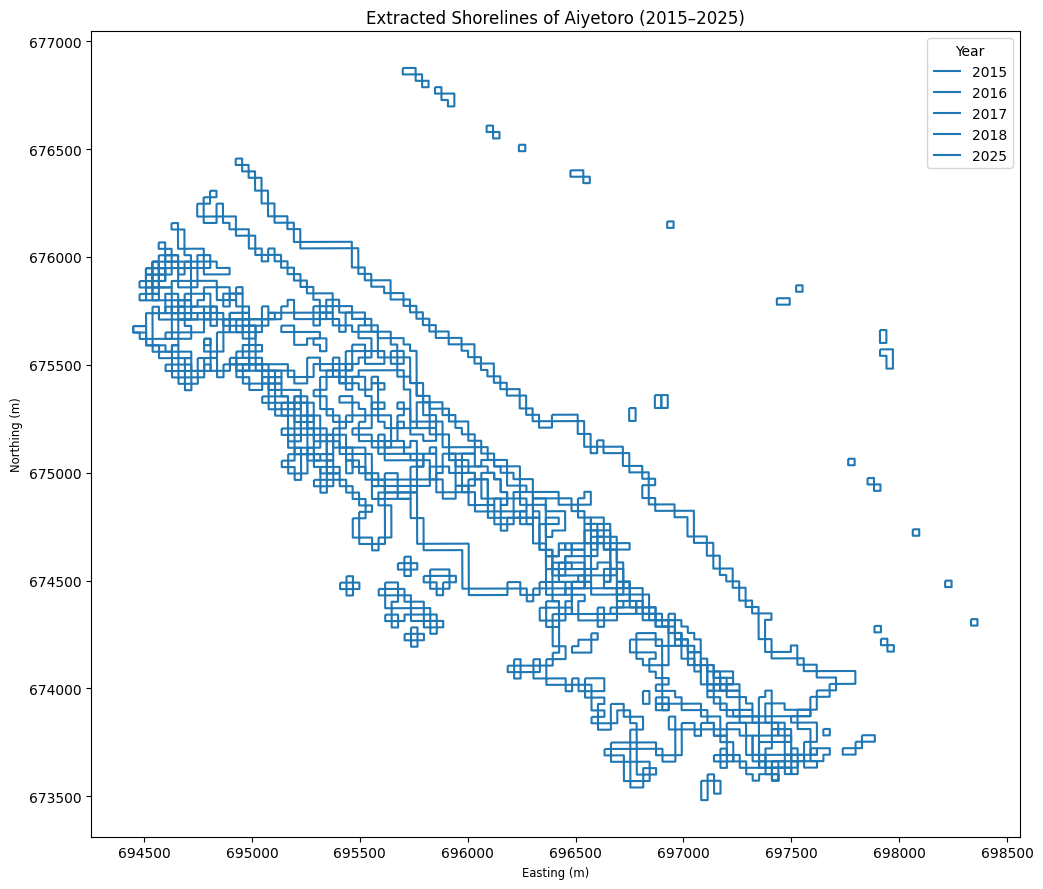

In [83]:
import geopandas as gpd
import matplotlib.pyplot as plt
import os

files = {
    2015: "/content/Shoreline_2015_Metres.gpkg..gpkg",
    2016: "/content/Shoreline_2016_Metres.gpkg",
    2017: "/content/Shoreline_2017_Metres.gpkg",
    2018: "/content/Shoreline_2018_Metres.gpkg",
    2025: "/content/Shoreline_2025_Metres.gpkg..gpkg"
}

fig, ax = plt.subplots(figsize=(12, 9))

for year, path in files.items():
    if not os.path.exists(path):
        print(f"Missing file: {path}")
        continue

    gdf = gpd.read_file(path)
    gdf = gdf.to_crs("EPSG:32631")

    gdf.plot(
        ax=ax,
        label=str(year),
        linewidth=1.5
    )

ax.set_title("Extracted Shorelines of Aiyetoro (2015–2025)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

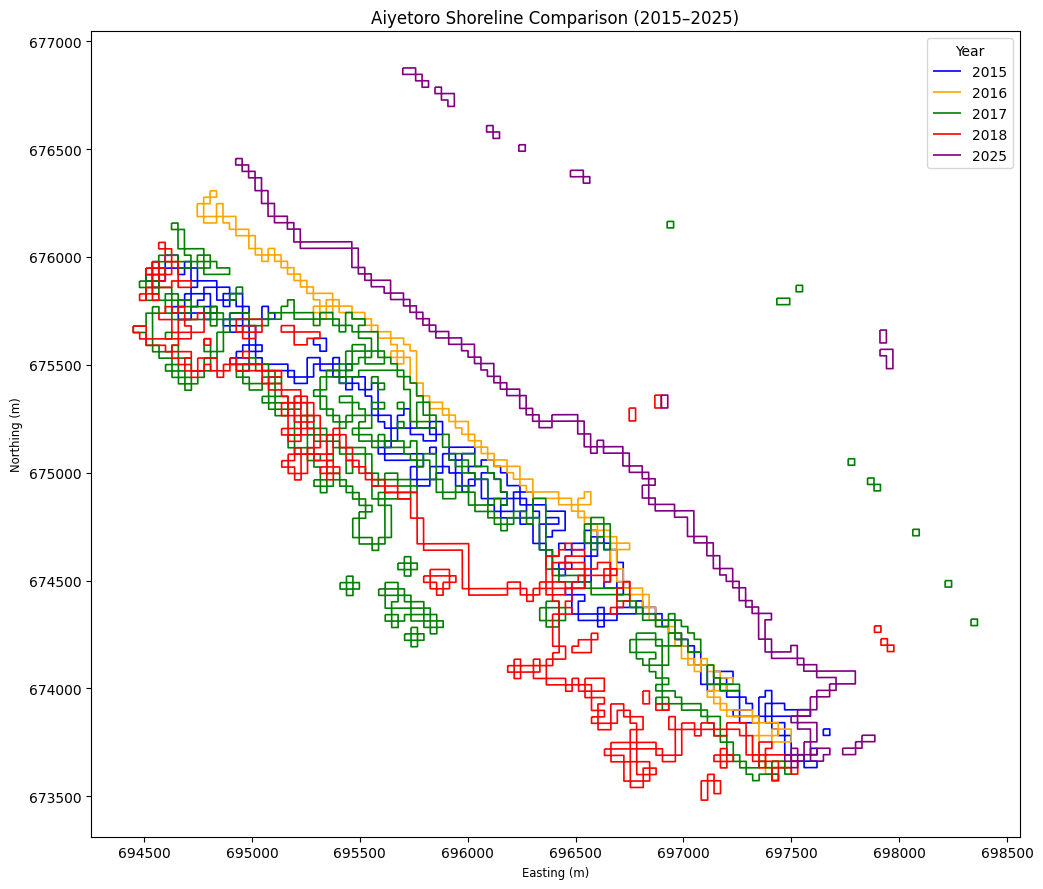

In [85]:
import geopandas as gpd
import matplotlib.pyplot as plt
import os

files = {
    2015: "/content/Shoreline_2015_Metres.gpkg..gpkg",
    2016: "/content/Shoreline_2016_Metres.gpkg",
    2017: "/content/Shoreline_2017_Metres.gpkg",
    2018: "/content/Shoreline_2018_Metres.gpkg",
    2025: "/content/Shoreline_2025_Metres.gpkg..gpkg"
}

fig, ax = plt.subplots(figsize=(12, 9))

colors = {
    2015: "blue",
    2016: "orange",
    2017: "green",
    2018: "red",
    2025: "purple"
}

for year, path in files.items():
    if not os.path.exists(path):
        print(f"Missing file: {path}")
        continue

    gdf = gpd.read_file(path).to_crs("EPSG:32631")

    gdf.plot(
        ax=ax,
        color=colors[year],
        linewidth=1.2,
        label=str(year)
    )

ax.set_title("Aiyetoro Shoreline Comparison (2015–2025)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(title="Year")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [86]:
# STEP 1: PREPARE DATA FOR PRELIMINARY XGBOOST

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap

# Load the existing spatial sample data
df = pd.read_csv(
    "/content/Aiyetoro_Spatial_Samples_Inspected.csv"
)

# Check required columns
required = [
    "Year",
    "Easting",
    "Northing",
    "Distance_to_2015_m"
]

missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Keep valid observations
df = df[required].replace([np.inf, -np.inf], np.nan).dropna()

# Define the exploratory target and predictors
X = df[["Year", "Easting", "Northing"]]
y = df["Distance_to_2015_m"]

print("Dataset shape:", df.shape)
print("\nObservations by year:")
print(df["Year"].value_counts().sort_index())

print("\nTarget variable: Distance_to_2015_m")
print("Predictors: Year, Easting, Northing")

Dataset shape: (1327, 4)

Observations by year:
Year
2016    180
2017    555
2018    389
2025    203
Name: count, dtype: int64

Target variable: Distance_to_2015_m
Predictors: Year, Easting, Northing


In [87]:
# STEP 2: TRAIN PRELIMINARY XGBOOST MODEL

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("PRELIMINARY XGBOOST RESULTS")
print("---------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f} m")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} m")
print(f"R-squared (R²): {r2:.3f}")

PRELIMINARY XGBOOST RESULTS
---------------------------
Mean Absolute Error (MAE): 76.19 m
Root Mean Squared Error (RMSE): 100.21 m
R-squared (R²): 0.853


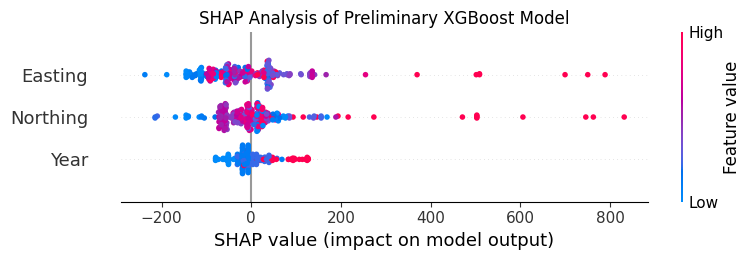


Feature Importance:


,Feature,Importance
2,Northing,0.512802
1,Easting,0.318454
0,Year,0.168744


In [88]:
# STEP 3: EXPLAIN MODEL PREDICTIONS WITH SHAP

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# SHAP summary plot
shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.title("SHAP Analysis of Preliminary XGBoost Model")
plt.tight_layout()
plt.show()

# Feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print("\nFeature Importance:")
display(importance)

In [89]:
# STEP 4: SAVE MODEL OUTPUTS

results = X_test.copy()
results["Actual_Distance_m"] = y_test
results["Predicted_Distance_m"] = y_pred
results.to_csv(
    "/content/Aiyetoro_XGBoost_Preliminary_Predictions.csv",
    index=False
)

importance.to_csv(
    "/content/Aiyetoro_XGBoost_Feature_Importance.csv",
    index=False
)

print("Preliminary prediction and feature-importance files saved.")

Preliminary prediction and feature-importance files saved.


XGBoost Feature Importance


,Feature,Importance
0,Northing,0.512802
1,Easting,0.318454
2,Year,0.168744


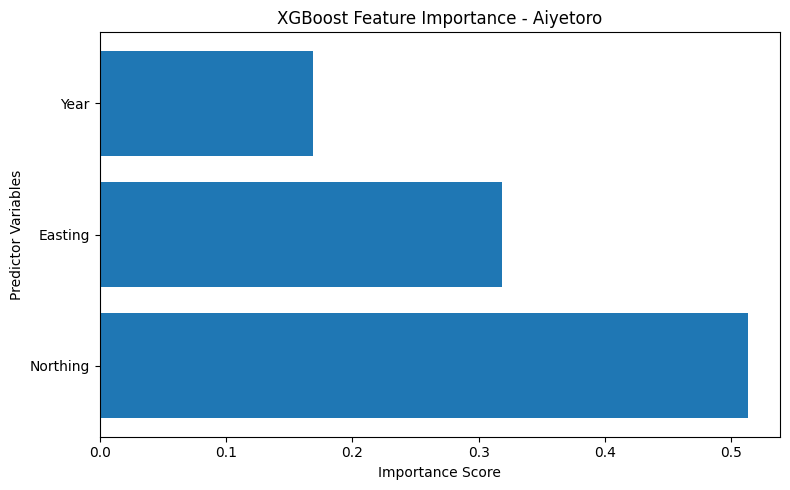

In [90]:
import pandas as pd
import matplotlib.pyplot as plt

# Load feature importance
importance = pd.read_csv(
    "/content/Aiyetoro_XGBoost_Feature_Importance.csv"
)

# Display the results
print("XGBoost Feature Importance")
display(importance)

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Predictor Variables")
plt.title("XGBoost Feature Importance - Aiyetoro")
plt.tight_layout()
plt.show()

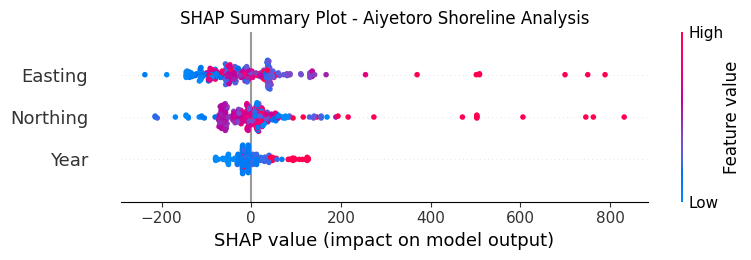

In [91]:
import shap
import matplotlib.pyplot as plt

# Explain the trained XGBoost model
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Generate SHAP summary plot
shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.title("SHAP Summary Plot - Aiyetoro Shoreline Analysis")
plt.tight_layout()
plt.show()